## 1. Setup

In [164]:
# Core libraries
import os, json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [165]:
# scikit-learn tools (each model imports its own estimator in its section)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, log_loss, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif

In [166]:
# Global settings
RANDOM_STATE = 42          # fixed seed so results are reproducible
TARGET = 'seasonal_vaccine'
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 50)

## 2. Load the data
Put `dataset_A_training.csv` and `dataset_A_testing.csv` in the Colab working folder (or the repo root).
If they are not found and we are running in Colab, an upload box appears.

In [167]:
TRAIN_PATH = 'dataset_A_training.csv'
TEST_PATH = 'dataset_A_testing.csv'

# In Colab, upload the files if they are not already present
if not (os.path.exists(TRAIN_PATH) and os.path.exists(TEST_PATH)):
    from google.colab import files
    files.upload()   # choose both CSV files

In [168]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print('Train shape:', train.shape)
print('Test shape :', test.shape)

Train shape: (4756, 31)
Test shape : (4749, 30)


In [169]:
train.head()

,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_seasonal,child_under_6_months,health_worker,health_insurance,opinion_seas_vacc_effective,opinion_seas_risk,opinion_seas_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,2.0,18 - 34 Years,12 Years,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,4.0,4.0,18 - 34 Years,Some College,White,Male,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,4.0,2.0,1.0,65+ Years,College Graduate,White,Male,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,NaN,0.0,0.0,1.0,3.0,3.0,1.0,55 - 64 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,NaN,3.0,1.0,1.0,55 - 64 Years,12 Years,White,Female,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


## 3. Exploratory data analysis
### 3.1 Structure and feature groups
Using the dataset information sheet, we group the features by type. The groups decide how each feature is pre-processed later.

In [170]:
# Binary (0/1) features
BINARY = ['behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
          'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
          'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months',
          'health_worker', 'health_insurance']

# Numeric ordinal scales and counts
ORDINAL_NUM = ['flu_concern', 'flu_knowledge', 'opinion_seas_vacc_effective',
               'opinion_seas_risk', 'opinion_seas_sick_from_vacc',
               'household_adults', 'household_children', 'number_chronic_med_conditions']

In [171]:
# Text categories that have a natural order (encoded as ranks in option B)
ORDERED_CAT = {
    'age_group': ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years'],
    'education': ['< 12 Years', '12 Years', 'Some College', 'College Graduate'],
    'income_poverty': ['Below Poverty', '<= $75,000, Above Poverty', '> $75,000'],
}

# Text categories with no order (one-hot encoded)
NOMINAL = ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status',
           'census_msa', 'employment_sector']

FEATURES = BINARY + ORDINAL_NUM + list(ORDERED_CAT) + NOMINAL
print(len(FEATURES), 'features')

29 features


In [172]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   flu_concern                    4744 non-null   float64
 2   flu_knowledge                  4733 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4724 non-null   float64
 5   behavioral_face_mask           4753 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4747 non-null   float64
 9   behavioral_touch_face          4737 non-null   float64
 10  doctor_recc_seasonal           4435 non-null   float64
 11  child_under_6_months           4604 non-null   float64
 12  health_worker                  4607 non-null   f

In [173]:
train[BINARY + ORDINAL_NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
behavioral_antiviral_meds,4742.0,0.05,0.22,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4724.0,0.73,0.44,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4753.0,0.07,0.26,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,0.84,0.37,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,0.37,0.48,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4747.0,0.34,0.47,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4737.0,0.69,0.46,0.0,0.0,1.0,1.0,1.0
doctor_recc_seasonal,4435.0,0.37,0.48,0.0,0.0,0.0,1.0,1.0
child_under_6_months,4604.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
health_worker,4607.0,0.14,0.34,0.0,0.0,0.0,0.0,1.0


In [174]:
# Data quality checks: duplicated rows and unique IDs
print('Duplicated rows (ignoring id):', train.duplicated(subset=FEATURES + [TARGET]).sum())
print('Unique train IDs:', train['respondent_id'].is_unique)
print('Train/test ID overlap:', len(set(train.respondent_id) & set(test.respondent_id)))

Duplicated rows (ignoring id): 0
Unique train IDs: True
Train/test ID overlap: 0


### 3.2 Target distribution

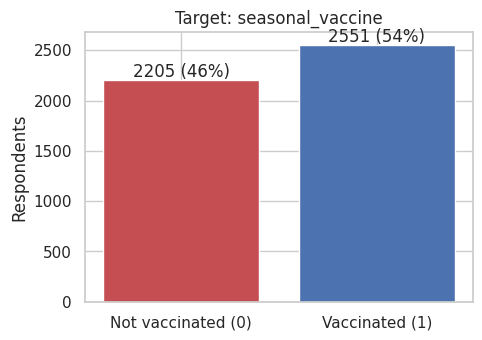

In [175]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = train[TARGET].value_counts().sort_index()
ax.bar(['Not vaccinated (0)', 'Vaccinated (1)'], counts.values, color=['#c44e52', '#4c72b0'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, f'{v} ({v / len(train):.0%})', ha='center')
ax.set_title('Target: seasonal_vaccine'); ax.set_ylabel('Respondents')
plt.show()

The classes are roughly balanced, so no resampling is needed. The **cost** of each error type matters far more than class balance (Section 4).

### 3.3 Missing values

In [176]:
# Percentage of missing values per column, train vs test
miss = pd.DataFrame({'train': train[FEATURES].isna().mean() * 100,
                     'test': test[FEATURES].isna().mean() * 100})
miss = miss[miss.train > 0].sort_values('train', ascending=False)
miss.round(1)

,train,test
employment_sector,48.7,50.6
health_insurance,40.5,41.7
income_poverty,16.6,16.8
rent_or_own,8.0,8.0
doctor_recc_seasonal,6.7,7.3
education,5.7,5.7
employment_status,5.7,5.8
marital_status,5.6,5.7
child_under_6_months,3.2,3.3
health_worker,3.1,3.1


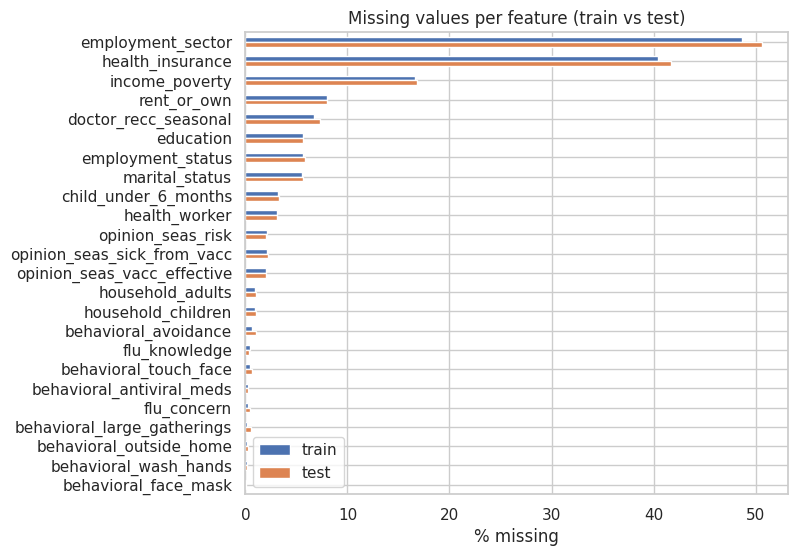

In [177]:
ax = miss.plot.barh(figsize=(7, 6), color=['#4c72b0', '#dd8452'])
ax.invert_yaxis(); ax.set_xlabel('% missing')
ax.set_title('Missing values per feature (train vs test)')
plt.show()

Is missingness itself informative? We compare the vaccination rate of respondents with and without a missing value.

In [178]:
# Vaccination rate when the value is missing vs present
rows = []
for col in miss.index:
    is_na = train[col].isna()
    rows.append({'feature': col,
                 'rate_if_missing': train.loc[is_na, TARGET].mean(),
                 'rate_if_present': train.loc[~is_na, TARGET].mean()})
miss_effect = pd.DataFrame(rows).set_index('feature').round(3)
miss_effect.head(8)

,rate_if_missing,rate_if_present
feature,,
employment_sector,0.568,0.506
health_insurance,0.462,0.587
income_poverty,0.513,0.541
rent_or_own,0.459,0.543
doctor_recc_seasonal,0.393,0.547
education,0.415,0.544
employment_status,0.416,0.544
marital_status,0.411,0.544


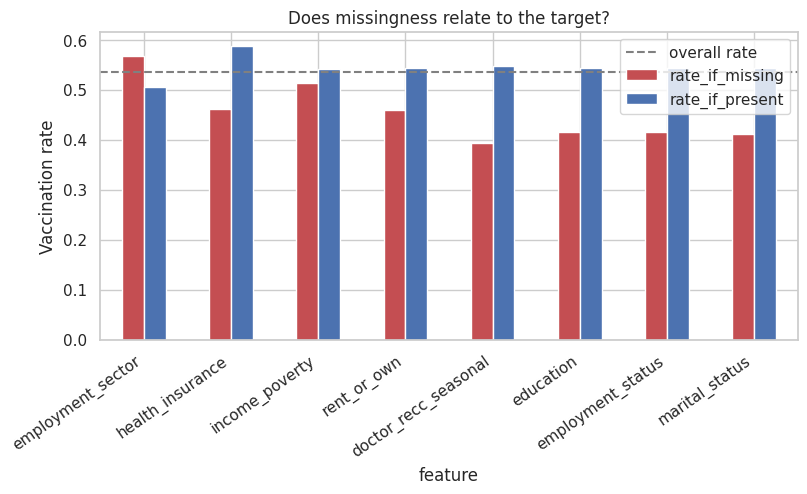

In [179]:
ax = miss_effect.head(8).plot.bar(figsize=(9, 4), color=['#c44e52', '#4c72b0'])
ax.axhline(train[TARGET].mean(), ls='--', c='grey', label='overall rate')
ax.set_ylabel('Vaccination rate'); ax.set_title('Does missingness relate to the target?')
ax.legend(); plt.xticks(rotation=35, ha='right'); plt.show()

In [180]:
# employment_sector is missing almost exactly when the person is not employed
pd.crosstab(train['employment_status'].fillna('Missing'),
            train['employment_sector'].isna().rename('sector_missing'))

sector_missing,False,True
employment_status,,
Employed,2442,25
Missing,0,269
Not in Labor Force,0,1786
Unemployed,0,234


**Findings on missing data**
- `employment_sector` (~49% missing) is **structurally missing**: it is blank for almost everyone who is not employed.
  Imputing the most frequent sector would be wrong, so we either drop it or give it its own category.
- `health_insurance` (~41% missing) is missing in a way that **relates to the target** (lower vaccination rate when missing),
  so a missing-value indicator should carry useful signal.
- Train and test have very similar missingness, so the same pre-processing will transfer to the test set.

### 3.4 Distributions of binary and ordinal features

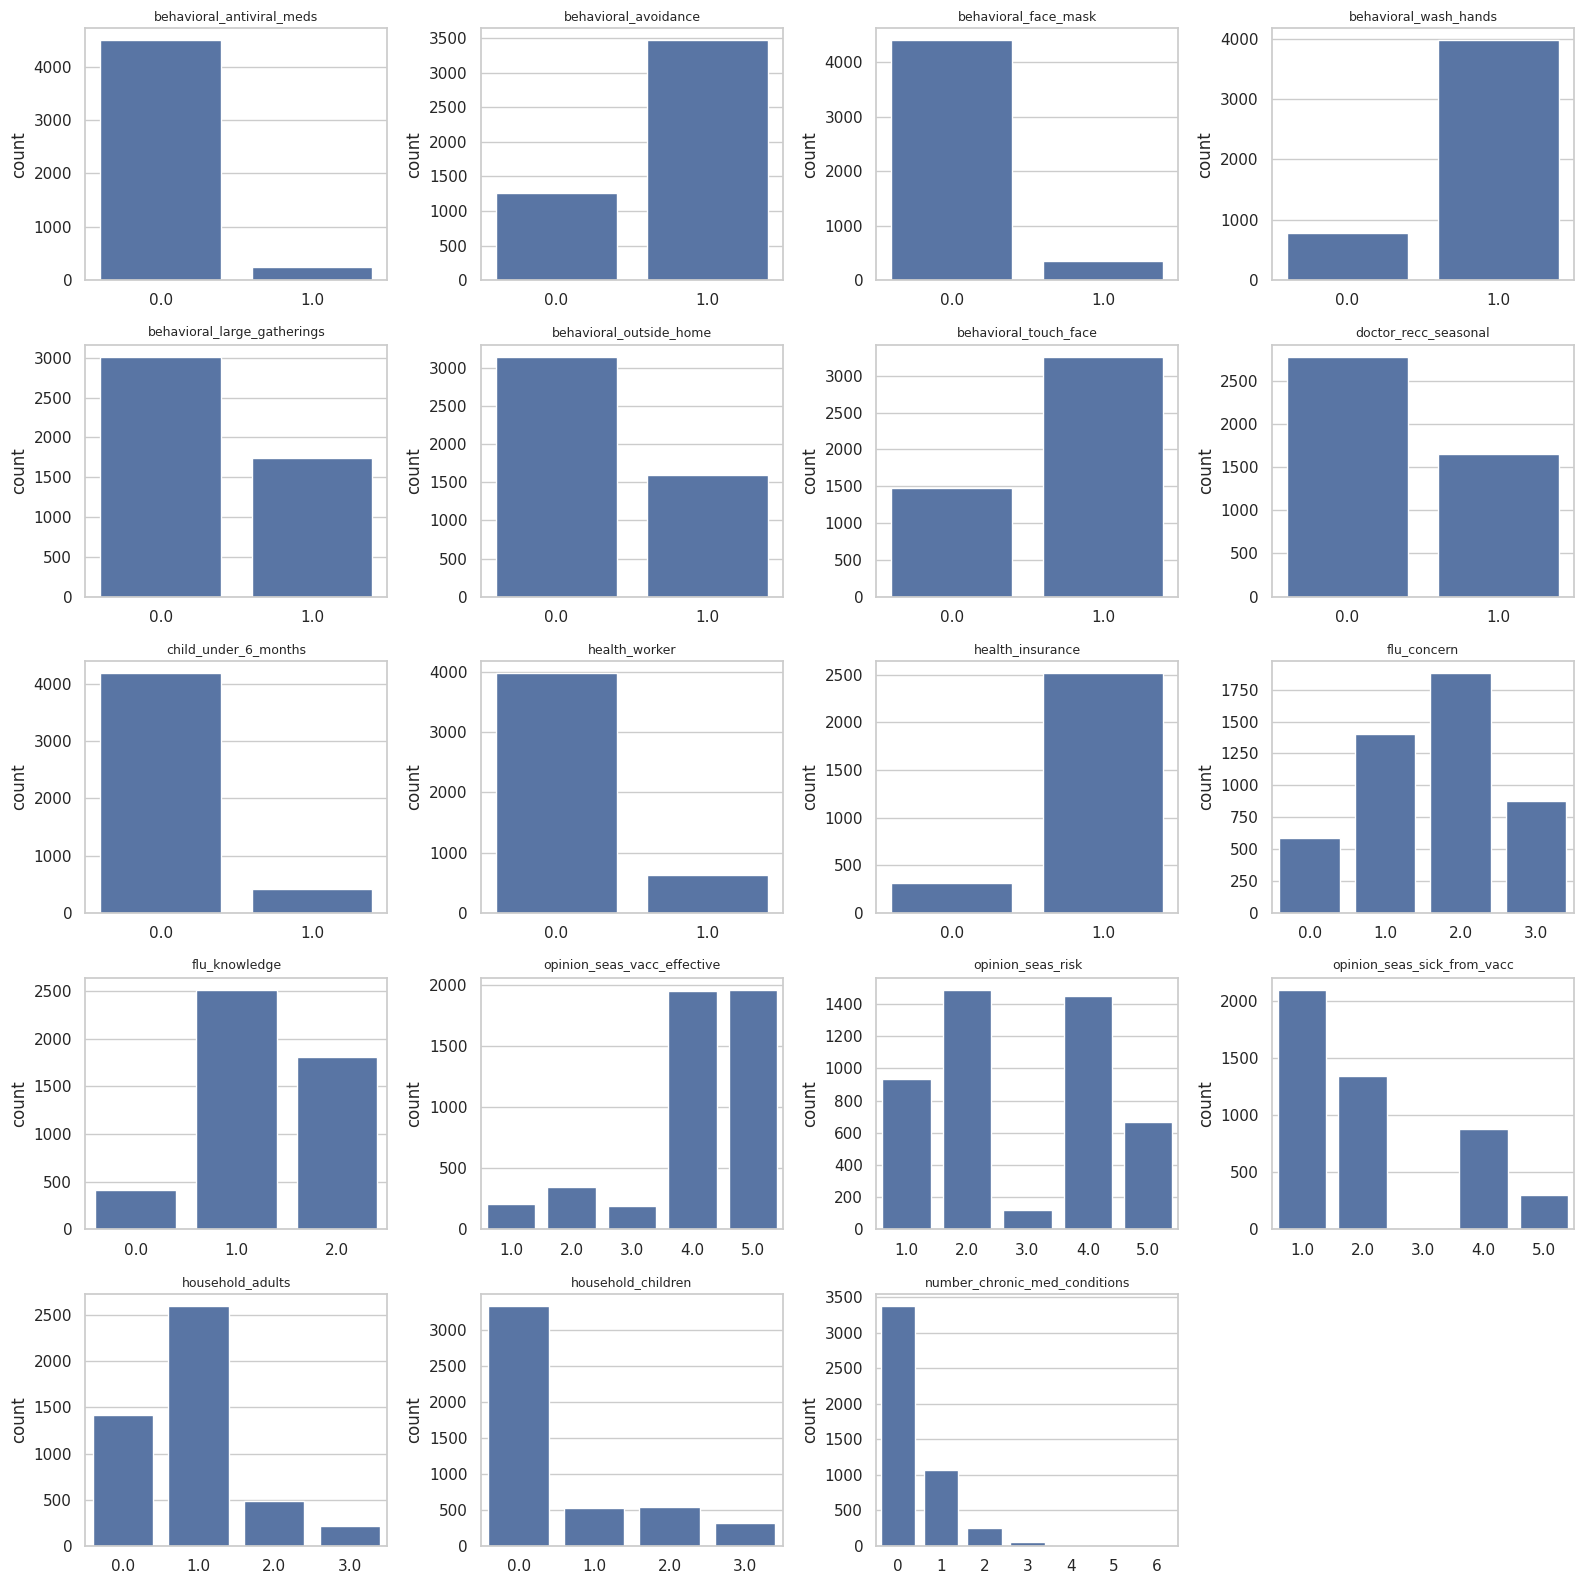

In [181]:
cols = BINARY + ORDINAL_NUM
fig, axes = plt.subplots(5, 4, figsize=(16, 16))
for ax, col in zip(axes.flat, cols):
    sns.countplot(x=train[col], ax=ax, color='#4c72b0')
    ax.set_title(col, fontsize=9); ax.set_xlabel('')
for ax in axes.flat[len(cols):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

### 3.5 Vaccination rate by feature
These plots show which features separate vaccinated from unvaccinated respondents.

In [182]:
def plot_rate(cols, ncols=4, order=None):
    """Bar plot of the vaccination rate for every level of each column."""
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows))
    for ax, col in zip(np.ravel(axes), cols):
        rate = train.groupby(train[col].fillna('Missing').astype(str))[TARGET].mean()
        if order and col in order:
            rate = rate.reindex([c for c in order[col] + ['Missing'] if c in rate.index])
        rate.plot.bar(ax=ax, color='#4c72b0')
        ax.axhline(train[TARGET].mean(), ls='--', c='grey')
        ax.set_title(col, fontsize=9); ax.set_xlabel(''); ax.set_ylim(0, 1)
        ax.tick_params(axis='x', labelsize=7, rotation=45)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

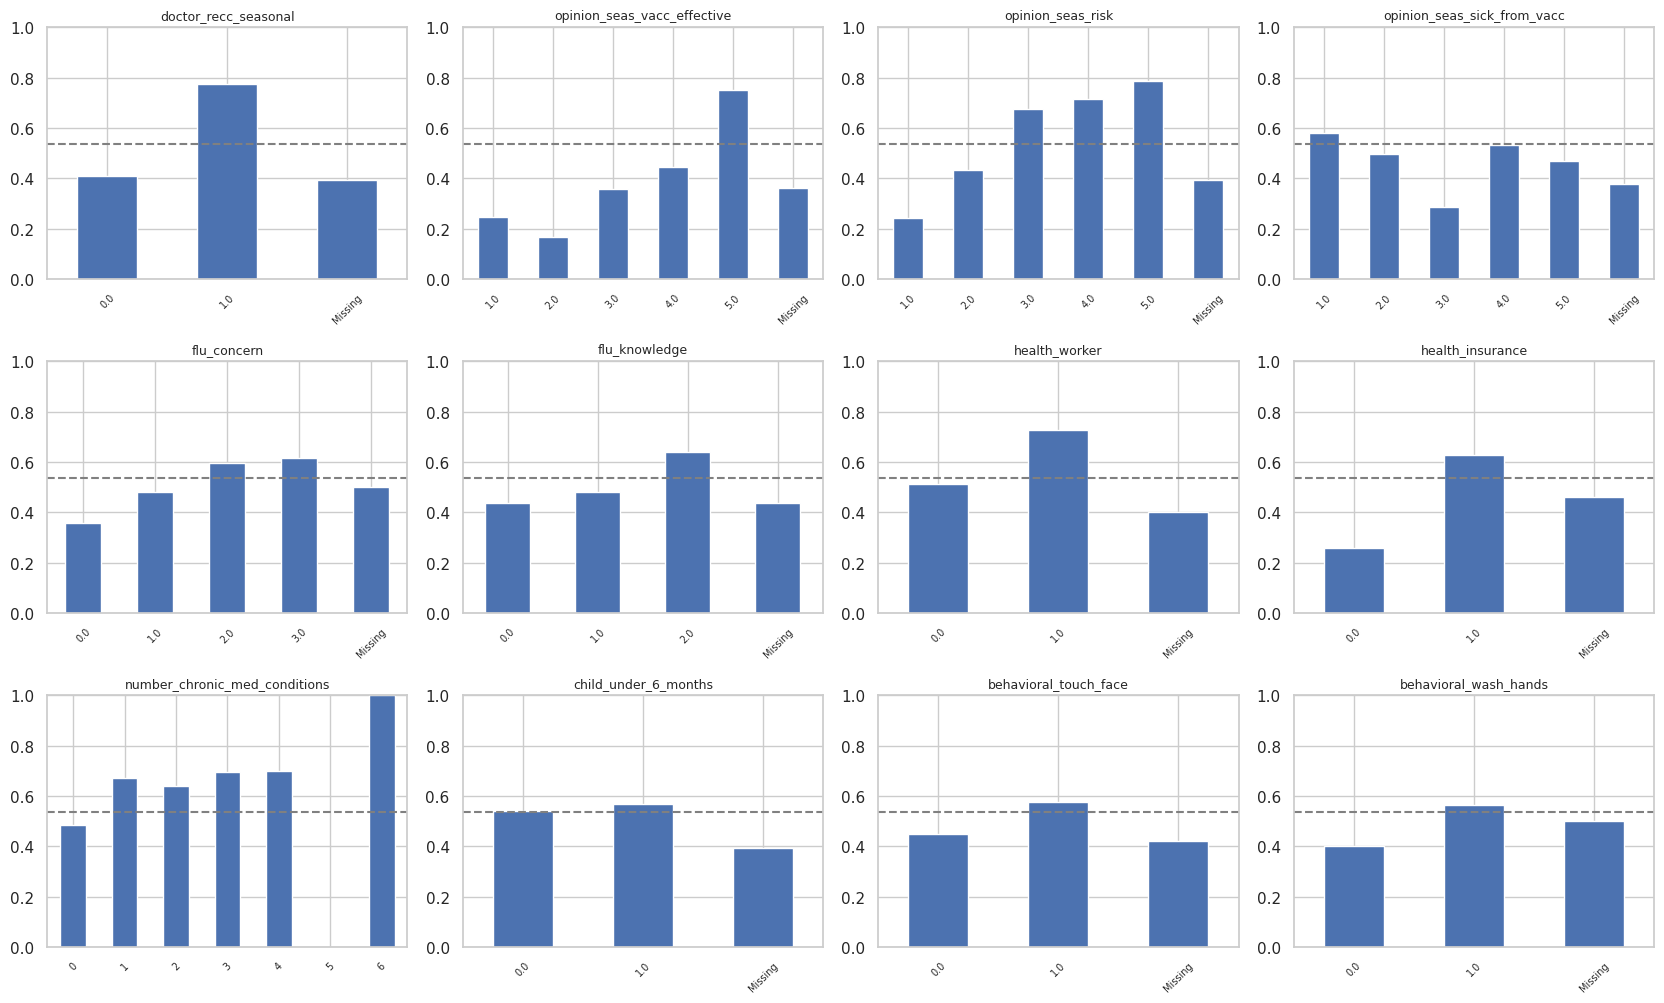

In [183]:
# Opinions, doctor recommendation and health-related features
plot_rate(['doctor_recc_seasonal', 'opinion_seas_vacc_effective', 'opinion_seas_risk',
           'opinion_seas_sick_from_vacc', 'flu_concern', 'flu_knowledge',
           'health_worker', 'health_insurance', 'number_chronic_med_conditions',
           'child_under_6_months', 'behavioral_touch_face', 'behavioral_wash_hands'])

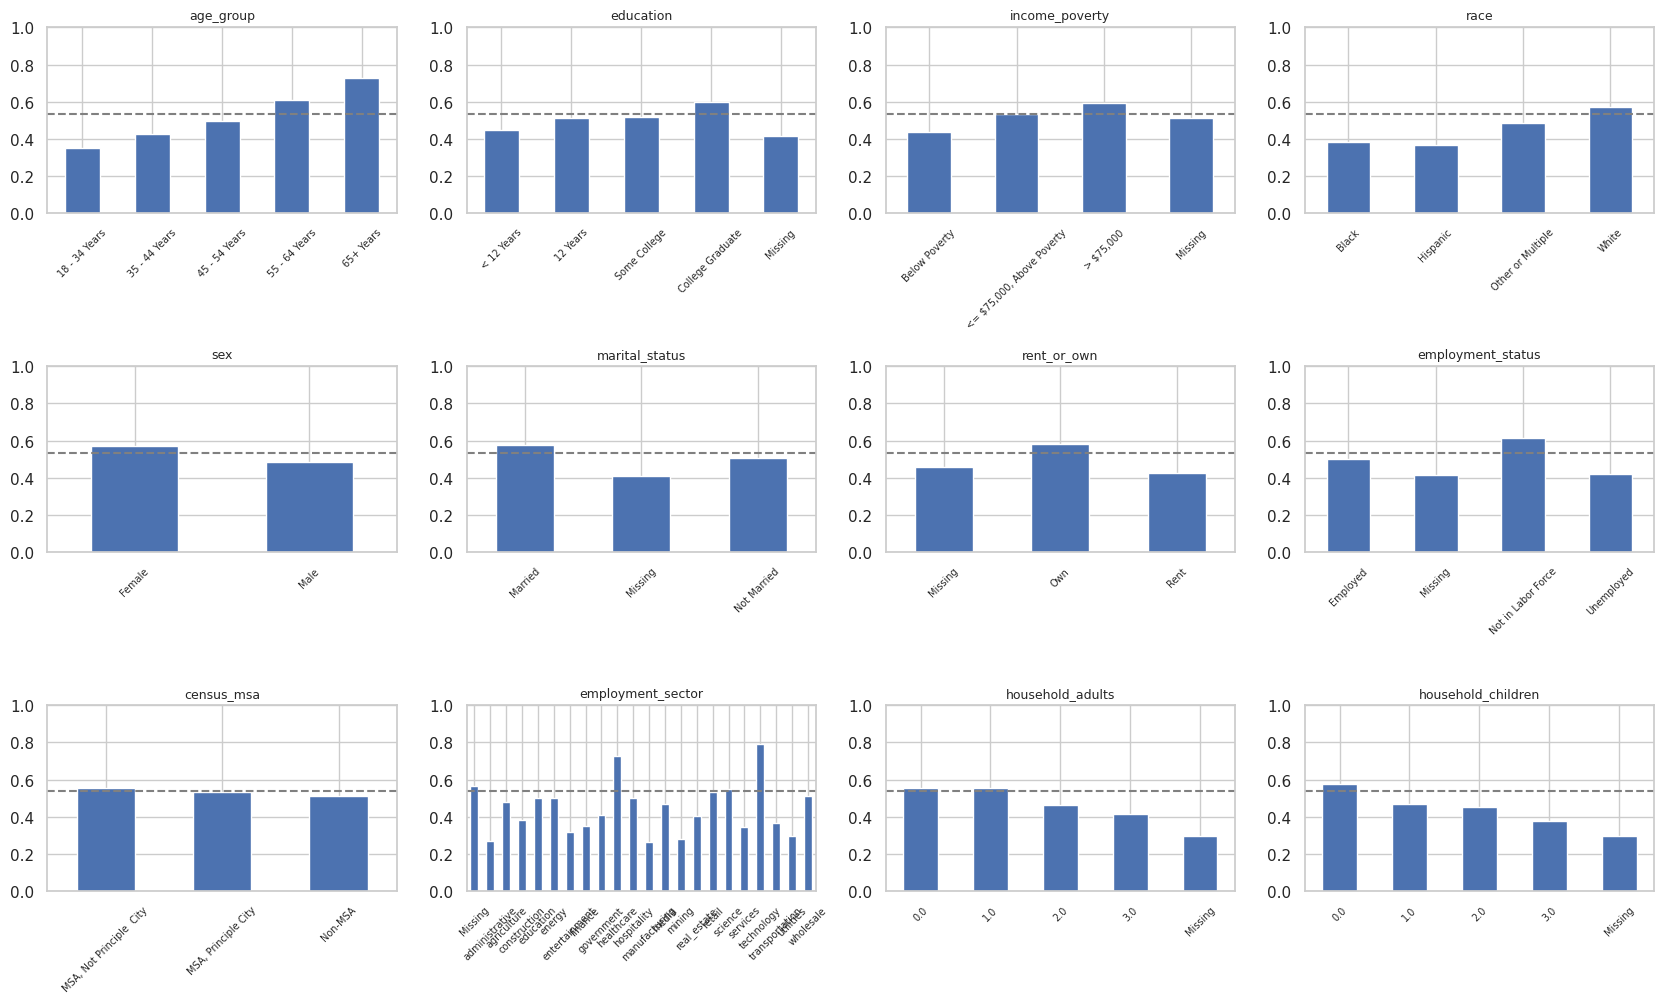

In [184]:
# Demographic features
plot_rate(list(ORDERED_CAT) + NOMINAL + ['household_adults', 'household_children'],
          order=ORDERED_CAT)

**Findings**
- **Doctor recommendation** is the strongest single signal: about 78% of those whose doctor recommended the vaccine took it, against about 41% of those whose doctor did not.
- **Age** has a clear monotonic effect (about 35% for 18–34 up to about 73% for 65+), which supports encoding it as an ordered rank.
- **Opinion on vaccine effectiveness** and **perceived risk** are strong. On these 1–5 scales, the "Don't know" level (3) does not
  always sit midway between its neighbours (e.g. risk = 3 has a higher rate than risk = 2). Treating the scales as numeric is a simplification that tree models can undo.
- Demographic features such as race, income and education have weaker but real effects.

### 3.6 Correlations between features

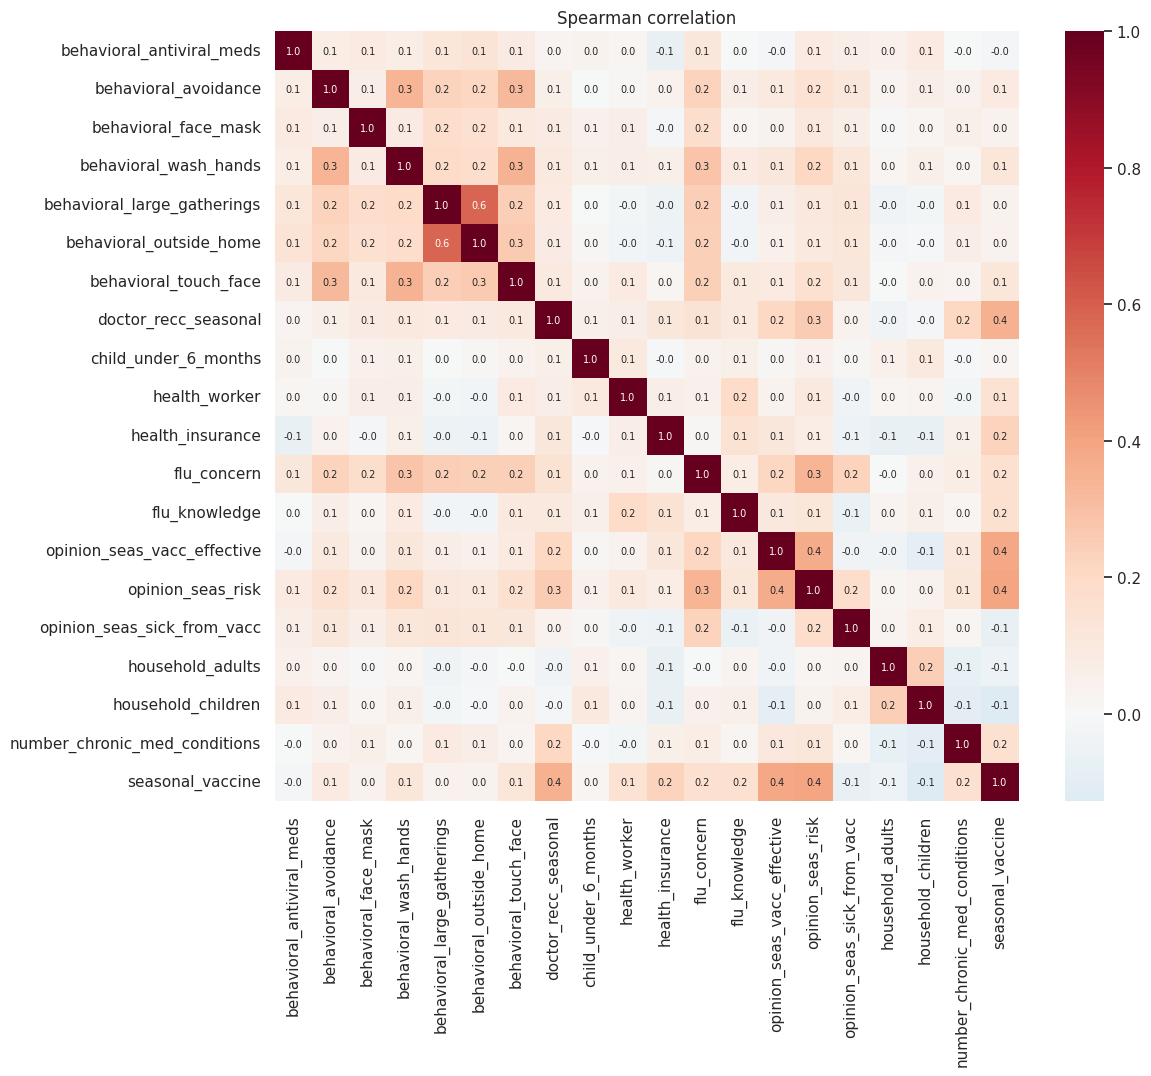

In [185]:
# Spearman correlation (suits ordinal scales)
corr = train[BINARY + ORDINAL_NUM + [TARGET]].corr(method='spearman')
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Spearman correlation'); plt.show()

The behavioural features correlate with each other but none correlate very strongly (|r| < 0.6), so multicollinearity is not a serious problem. We keep all features; L2 regularisation in logistic regression handles the moderate overlap.

### 3.7 Feature relevance (mutual information)
Mutual information captures non-linear dependence with the target for every feature, including categoricals.

In [186]:
# Quick numeric encoding just for this analysis (missing -> -1)
mi_X = train[FEATURES].copy()
for col in list(ORDERED_CAT) + NOMINAL:
    mi_X[col] = mi_X[col].astype('category').cat.codes
mi_X = mi_X.fillna(-1)
mi = mutual_info_classif(mi_X, train[TARGET], discrete_features=True, random_state=RANDOM_STATE)
mi = pd.Series(mi, index=FEATURES).sort_values()

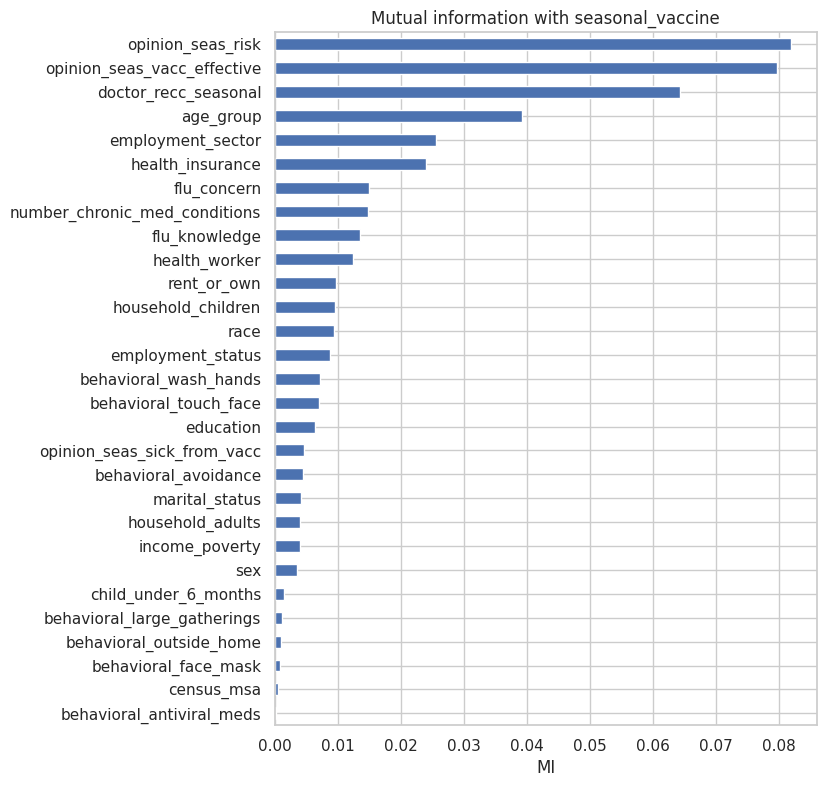

In [187]:
mi.plot.barh(figsize=(7, 9), color='#4c72b0')
plt.title('Mutual information with seasonal_vaccine'); plt.xlabel('MI')
plt.show()

### 3.8 Train vs test similarity
If the test set looks like the training set, cross-validation scores should carry over to the hidden test results.

In [188]:
shift = pd.DataFrame({'train_mean': train[BINARY + ORDINAL_NUM].mean(),
                      'test_mean': test[BINARY + ORDINAL_NUM].mean()})
shift['abs_diff'] = (shift.train_mean - shift.test_mean).abs()
shift.sort_values('abs_diff', ascending=False).round(3).head(8)

,train_mean,test_mean,abs_diff
flu_concern,1.643,1.691,0.048
opinion_seas_risk,2.877,2.917,0.040
household_adults,0.896,0.875,0.021
opinion_seas_vacc_effective,4.095,4.112,0.017
household_children,0.542,0.528,0.014
flu_knowledge,1.293,1.282,0.011
health_insurance,0.889,0.899,0.010
health_worker,0.137,0.130,0.007


The differences are tiny, so the test set comes from the same distribution as the training set.

## 4. Finding the evaluation metric
We are told to minimise a task-specific measure of prediction error, and we are given two costs:

| Item | Cost |
|---|---|
| Seasonal (H3N2) vaccine | \$300 |
| Hospitalisation for H3N2 flu | \$18,500 |

**How the predictions are used.** A public-health team uses the model to decide **who to contact and offer a vaccine**:
- If the model predicts **1 (already vaccinated)**, the person is **not** contacted.
- If the model predicts **0 (not vaccinated)**, the person is offered a vaccine.

**What each error costs**

| | Actually vaccinated (1) | Actually not vaccinated (0) |
|---|---|---|
| **Predict 1** | TP: correct, \$0 | **FP: person left unprotected → risk of hospitalisation, \$18,500** |
| **Predict 0** | **FN: unnecessary vaccine, \$300** | TN: correct, \$0 |

$$\text{Total cost} = 18{,}500 \times FP + 300 \times FN$$

A false positive is about **62× more expensive** than a false negative, so accuracy, F1 and other symmetric metrics are the wrong target.

In [189]:
COSTS = {'TP': 0, 'TN': 0, 'FP': 18_500, 'FN': 300}

def total_cost(y_true, y_pred, costs=COSTS):
    """Total $ cost of a set of 0/1 predictions."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tp * costs['TP'] + tn * costs['TN'] + fp * costs['FP'] + fn * costs['FN']

In [190]:
def cost_per_person(y_true, y_pred, costs=COSTS):
    """Average cost per respondent, so data sets of different sizes can be compared."""
    return total_cost(y_true, y_pred, costs) / len(y_true)

**The cost-optimal decision threshold.** If a model gives probability $p$ that a person is vaccinated:
- predicting 1 has expected cost $(1-p) \times 18{,}500$
- predicting 0 has expected cost $p \times 300$

So we should predict 1 only when $p > \dfrac{C_{FP}-C_{TN}}{(C_{FP}-C_{TN}) + (C_{FN}-C_{TP})} = \dfrac{18{,}500}{18{,}800} \approx 0.984$.
The default 0.5 threshold would be very costly. This only works if the probabilities are **well calibrated**, so we tune models on log loss and check how many people pass the threshold (Sections 6–10).

In [191]:
def bayes_threshold(costs=COSTS):
    """Probability above which predicting 1 has a lower expected cost than predicting 0."""
    a = costs['FP'] - costs['TN']
    b = costs['FN'] - costs['TP']
    return a / (a + b)

THRESHOLD = bayes_threshold()
print(f'Theoretical cost-optimal threshold: {THRESHOLD:.4f}')

Theoretical cost-optimal threshold: 0.9840


In [192]:
# Reference policies on the training data
y_all = train[TARGET]
for name, pred in {'Predict all 0 (offer everyone a vaccine)': np.zeros(len(y_all)),
                   'Predict all 1 (contact no one)': np.ones(len(y_all)),
                   'Predict truth (perfect model)': y_all}.items():
    print(f'{name:45s} ${cost_per_person(y_all, pred):8.2f} per person')

Predict all 0 (offer everyone a vaccine)      $  160.91 per person
Predict all 1 (contact no one)                $ 8577.06 per person
Predict truth (perfect model)                 $    0.00 per person


**Key insight.** Offering everyone a vaccine costs \$300 for each person who is already vaccinated (about \$161 per person), whereas wrongly
skipping an unvaccinated person costs \$18,500. Our model must beat the **"predict all 0" baseline**. To do that, it has to find people it is
almost certain (above 98.4%) are already vaccinated. Accuracy-oriented models will not do this, which is why the metric drives every later choice.

## 5. Pre-processing, hold-out split and cross-validation
- **Option A – simple:** median / most-frequent imputation, one-hot encoding, `employment_sector` dropped.
- **Option B – missing-aware:** missing-value indicators, ordered categories as ranks, missing nominal values as their own category `'Missing'`.

In [193]:
prep_A = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), BINARY + ORDINAL_NUM),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]),
     list(ORDERED_CAT) + [c for c in NOMINAL if c != 'employment_sector']),
])

In [194]:
ordinal_pipe = Pipeline([
    ('encode', OrdinalEncoder(categories=list(ORDERED_CAT.values()),
                              handle_unknown='use_encoded_value', unknown_value=np.nan,
                              encoded_missing_value=np.nan)),
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler()),
])

In [195]:
prep_B = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scale', StandardScaler())]), BINARY + ORDINAL_NUM),
    ('ord', ordinal_pipe, list(ORDERED_CAT)),
    ('nom', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), NOMINAL),
])

In [196]:
# 80% development set (tuning + CV) / 20% hold-out set
X, y = train[FEATURES], train[TARGET]
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

In [197]:
def make_pipe(prep, model):
    """Pre-processor + model, so pre-processing is learnt inside each CV fold (no leakage)."""
    return Pipeline([('prep', clone(prep)), ('model', model)])

def evaluate_cv(model, X, y, cv=CV, threshold=THRESHOLD):
    """Per-fold cost per person, AUC and log loss on the validation folds."""
    rows = []
    for tr_idx, va_idx in cv.split(X, y):
        m = clone(model).fit(X.iloc[tr_idx], y.iloc[tr_idx])
        p = m.predict_proba(X.iloc[va_idx])[:, 1]
        y_va = y.iloc[va_idx]
        rows.append({'cost_pp': cost_per_person(y_va, (p >= threshold).astype(int)),
                     'auc': roc_auc_score(y_va, p), 'log_loss': log_loss(y_va, p, labels=[0, 1])})
    return pd.DataFrame(rows)

In [198]:
# Baseline to beat: predict everyone as 0 (offer everyone a vaccine)
BASELINE_PP = cost_per_person(y_dev, np.zeros(len(y_dev)))
print(f'Baseline cost per person (development set): ${BASELINE_PP:.2f}')

Baseline cost per person (development set): $160.88


## 6. Logistic Regression

### Why this model
Logistic regression is a linear model of the log-odds of being vaccinated. It is fast, easy to interpret through its coefficients,
and its probabilities are usually well calibrated. Calibration matters here because our decision threshold (0.984) sits at the very top of the probability scale.
L2 regularisation (`C`) controls overfitting.

In [199]:
from sklearn.linear_model import LogisticRegression

MODEL_NAME = 'LogReg'
base_model = LogisticRegression(max_iter=2000)

#### Pre-processing option A vs option B
Untuned model, 5-fold CV on the development set.

In [200]:
prep_results = []
for prep_name, prep in {'A_simple': prep_A, 'B_missing_aware': prep_B}.items():
    res = evaluate_cv(make_pipe(prep, base_model), X_dev, y_dev)
    res['prep'] = prep_name
    prep_results.append(res)
prep_results = pd.concat(prep_results, ignore_index=True)

In [201]:
prep_results.groupby('prep').agg(['mean', 'std']).round(4)

cost_pp              auc         log_loss        
                     mean      std    mean     std     mean     std
prep                                                               
A_simple         164.4047  10.7473  0.8419  0.0078   0.4958  0.0121
B_missing_aware  168.3989  14.4158  0.8456  0.0064   0.4946  0.0109

In [202]:
# Choose the option with the lower log loss (better probabilities) for tuning
prep_ll = prep_results.groupby('prep')['log_loss'].mean()
BEST_PREP_NAME = prep_ll.idxmin()
best_prep = {'A_simple': prep_A, 'B_missing_aware': prep_B}[BEST_PREP_NAME]
print('Pre-processing used from here on:', BEST_PREP_NAME)

Pre-processing used from here on: B_missing_aware


### Hyper-parameter tuning
`RandomizedSearchCV` with 5-fold CV, scored on **log loss**. Log loss is a smooth measure of probability quality, and the cost decision depends on
reliable probabilities. Cost itself only changes when a respondent crosses the 0.984 threshold, so it is too noisy to tune on directly.

In [203]:
param_grid = {'model__C': np.logspace(-3, 1, 20)}   # smaller C = stronger L2 regularisation

In [204]:
search = RandomizedSearchCV(make_pipe(best_prep, base_model), param_grid, n_iter=20,
                            cv=CV, scoring='neg_log_loss', random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_dev, y_dev)
tuned_model = search.best_estimator_
print('Best CV log loss:', round(-search.best_score_, 4))
print('Best parameters:', search.best_params_)

Best CV log loss: 0.4929
Best parameters: {'model__C': np.float64(0.029763514416313176)}


In [205]:
# Top 5 parameter combinations tried
cv_res = pd.DataFrame(search.cv_results_)
cv_res['log_loss'] = -cv_res['mean_test_score']
cv_res.sort_values('log_loss')[['params', 'log_loss', 'std_test_score']].head(5)

,params,log_loss,std_test_score
7,{'model__C': 0.029763514416313176},0.492929,0.009969
8,{'model__C': 0.04832930238571752},0.492965,0.009872
9,{'model__C': 0.07847599703514611},0.493038,0.009762
10,{'model__C': 0.12742749857031335},0.493080,0.009625
6,{'model__C': 0.018329807108324356},0.493135,0.009949


### Cost against decision threshold
Out-of-fold probabilities (each respondent is predicted by a model that did not train on them), then the cost of every threshold.

In [206]:
oof = cross_val_predict(tuned_model, X_dev, y_dev, cv=CV, method='predict_proba')[:, 1]
thresholds = np.linspace(0.80, 1.0, 201)
oof_costs = [cost_per_person(y_dev, (oof >= t).astype(int)) for t in thresholds]
print(f'OOF AUC {roc_auc_score(y_dev, oof):.4f} | OOF log loss {log_loss(y_dev, oof):.4f}')

OOF AUC 0.8451 | OOF log loss 0.4929


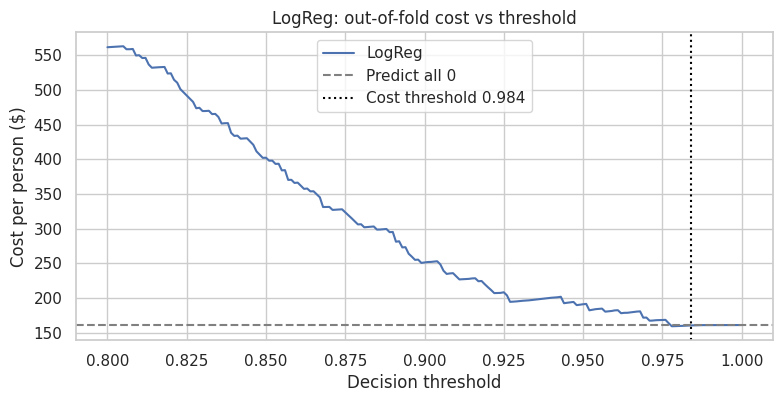

In [207]:
plt.figure(figsize=(9, 4))
plt.plot(thresholds, oof_costs, label=MODEL_NAME)
plt.axhline(BASELINE_PP, ls='--', c='grey', label='Predict all 0')
plt.axvline(THRESHOLD, ls=':', c='black', label=f'Cost threshold {THRESHOLD:.3f}')
plt.xlabel('Decision threshold'); plt.ylabel('Cost per person ($)')
plt.title(f'{MODEL_NAME}: out-of-fold cost vs threshold'); plt.legend(); plt.show()

In [208]:
# Respondents above the cost threshold, and how many of them are really vaccinated
sure = oof >= THRESHOLD
print(f'Predicted 1: {sure.sum()} of {len(oof)}')
if sure.any():
    print(f'Share truly vaccinated among them: {y_dev[sure].mean():.3f}  (needs to be above {THRESHOLD:.3f})')
print(f'OOF cost per person: ${cost_per_person(y_dev, sure.astype(int)):.2f}  vs baseline ${BASELINE_PP:.2f}')

Predicted 1: 7 of 3804
Share truly vaccinated among them: 1.000  (needs to be above 0.984)
OOF cost per person: $160.33  vs baseline $160.88


### Repeated cross-validation (robustness)
5-fold CV repeated 3 times (15 fits) at the cost threshold, to measure how much the cost varies from one data split to another.

In [209]:
rcv = evaluate_cv(tuned_model, X_dev, y_dev, cv=RCV)
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
rcv['baseline_pp'] = baseline_folds
rcv['saving_pp'] = rcv['baseline_pp'] - rcv['cost_pp']
rcv.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,cost_pp,auc,log_loss,baseline_pp,saving_pp
mean,160.252,0.847,0.491,160.883,0.631
std,0.461,0.015,0.021,0.088,0.442
min,159.264,0.828,0.433,160.841,0.000
max,160.841,0.892,0.522,161.053,1.577


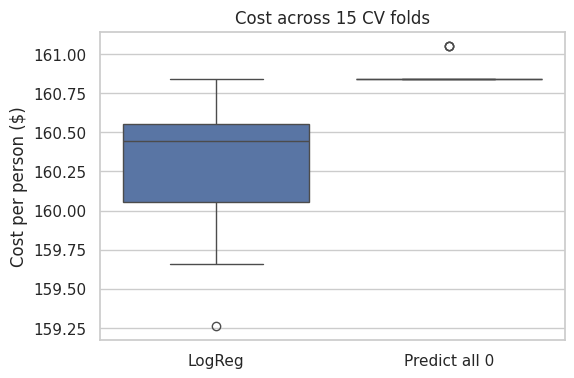

In [210]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=rcv[['cost_pp', 'baseline_pp']].rename(
    columns={'cost_pp': MODEL_NAME, 'baseline_pp': 'Predict all 0'}))
plt.ylabel('Cost per person ($)'); plt.title('Cost across 15 CV folds'); plt.show()

In [211]:
print(f'Mean saving vs baseline: ${rcv.saving_pp.mean():.2f} per person '
      f'(folds where the model beats or matches the baseline: {(rcv.saving_pp >= 0).mean():.0%})')

Mean saving vs baseline: $0.63 per person (folds where the model beats or matches the baseline: 100%)


### Hold-out validation (unseen data)
Fit on the full development set and score once on the 20% hold-out set.

In [212]:
dev_model = clone(tuned_model).fit(X_dev, y_dev)
p_hold = dev_model.predict_proba(X_hold)[:, 1]
pred_hold = (p_hold >= THRESHOLD).astype(int)
hold_baseline = cost_per_person(y_hold, np.zeros(len(y_hold)))

In [213]:
print(f'Hold-out AUC: {roc_auc_score(y_hold, p_hold):.4f}')
print(f'Hold-out cost per person: ${cost_per_person(y_hold, pred_hold):.2f}  (baseline ${hold_baseline:.2f})')
print(f'Hold-out total cost: ${total_cost(y_hold, pred_hold):,}   predicted 1: {pred_hold.sum()}')

Hold-out AUC: 0.8516
Hold-out cost per person: $160.71  (baseline $161.03)
Hold-out total cost: $153,000   predicted 1: 1


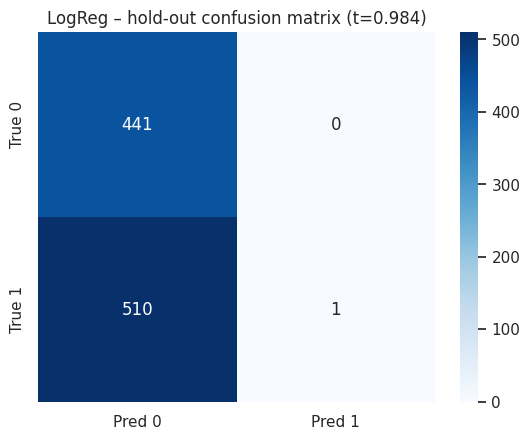

In [214]:
cm = confusion_matrix(y_hold, pred_hold, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
plt.title(f'{MODEL_NAME} – hold-out confusion matrix (t={THRESHOLD:.3f})'); plt.show()

In [215]:
# The same model at the default 0.5 threshold, for contrast
pred_05 = (p_hold >= 0.5).astype(int)
for name, pred in {'t=0.5': pred_05, f't={THRESHOLD:.3f}': pred_hold}.items():
    print(f'{name:8s} accuracy={(pred == y_hold).mean():.3f}  cost per person=${cost_per_person(y_hold, pred):,.2f}')

t=0.5    accuracy=0.777  cost per person=$2,207.98
t=0.984  accuracy=0.464  cost per person=$160.71


### Explaining the model

#### Coefficients
Features are standardised, so coefficient size is comparable: positive = more likely to be vaccinated.

In [216]:
feat_names = dev_model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(dev_model.named_steps['model'].coef_[0], index=feat_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(20).sort_values()

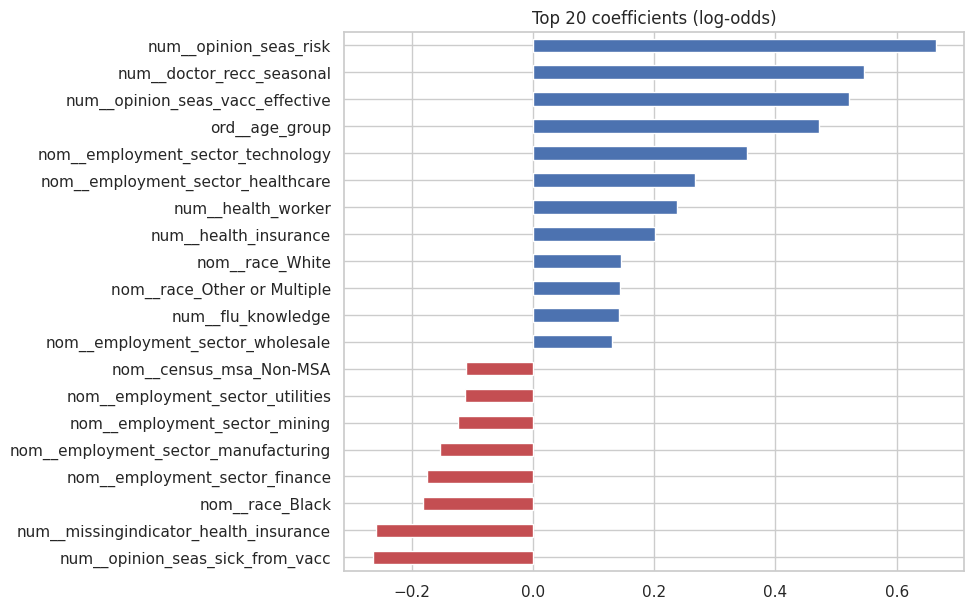

In [217]:
top.plot.barh(figsize=(8, 7), color=np.where(top > 0, '#4c72b0', '#c44e52'))
plt.title('Top 20 coefficients (log-odds)'); plt.show()

#### Permutation importance on the hold-out set
Model-agnostic: how much hold-out log loss gets worse when one original feature is shuffled.

In [218]:
perm = permutation_importance(dev_model, X_hold, y_hold, scoring='neg_log_loss',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

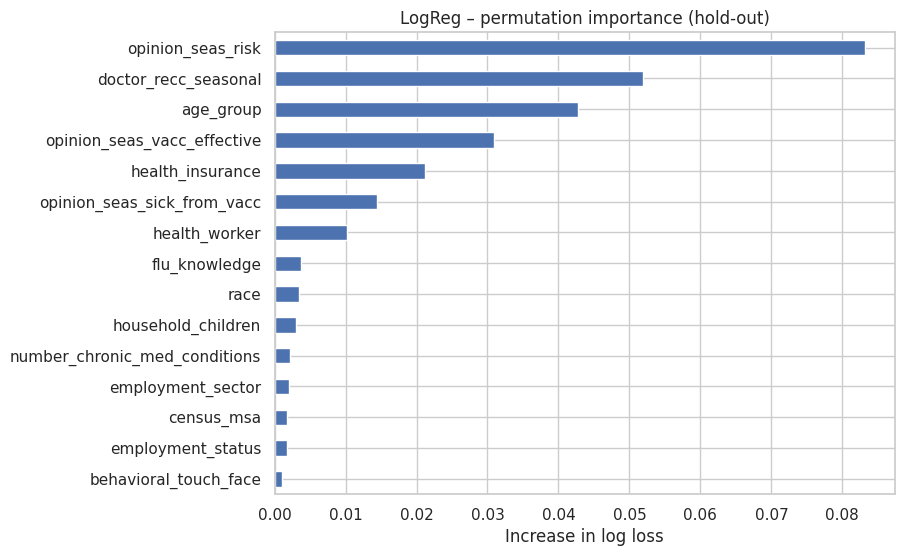

In [219]:
perm_imp.tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – permutation importance (hold-out)'); plt.xlabel('Increase in log loss')
plt.show()

#### Summary of findings – Logistic Regression
- **Pre-processing:** Option B (missing-aware) gives the better log loss, so it was used for tuning.
- **Tuning:** the best `C` is about 0.03, which means strong regularisation. It shrinks the coefficients, so the model only becomes very confident about clear-cut respondents.
- **Cost:** on out-of-fold predictions it flags 7 respondents above the 0.984 threshold, **all truly vaccinated**. Across 15 repeated-CV folds it saves about
  **\$0.63 per person** against vaccinating everyone, and it beats or matches the baseline on **every fold**.
- **Hold-out:** \$160.71 per person against \$161.03 for the baseline. At the default 0.5 threshold it would cost \$2,208 per person.
- **Drivers:** perceived risk, doctor recommendation, age and opinion on vaccine effectiveness. Worry about getting sick from the vaccine and a missing health-insurance answer lower the probability.

### Save results and test predictions
- `results/<model>_results.json` holds the numbers used by Section 11.
- `results/<model>_holdout_proba.csv` holds hold-out probabilities (used for the cost sensitivity analysis).
- `results/<model>_test_predictions.csv` holds test-set predictions from the model refitted on **all** labelled data.

In [220]:
os.makedirs('results', exist_ok=True)
results = {
    'model': MODEL_NAME,
    'preprocessing': BEST_PREP_NAME,
    'best_params': {k: str(v) for k, v in search.best_params_.items()},
    'cv_log_loss': float(-search.best_score_),
    'rcv_cost_pp_folds': rcv['cost_pp'].round(4).tolist(),
    'rcv_cost_pp_mean': float(rcv['cost_pp'].mean()),
    'rcv_cost_pp_std': float(rcv['cost_pp'].std()),
    'rcv_auc_mean': float(rcv['auc'].mean()),
    'holdout_cost_pp': float(cost_per_person(y_hold, pred_hold)),
    'holdout_cost_pp_t05': float(cost_per_person(y_hold, pred_05)),
    'holdout_auc': float(roc_auc_score(y_hold, p_hold)),
}

In [221]:
with open(f'results/{MODEL_NAME}_results.json', 'w') as f:
    json.dump(results, f, indent=2)
pd.DataFrame({'p': p_hold}, index=X_hold.index).to_csv(f'results/{MODEL_NAME}_holdout_proba.csv')

In [222]:
# Refit on all labelled data (development + hold-out) and predict the test set
final_model = clone(tuned_model).fit(X, y)
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
sub = pd.DataFrame({'respondent_id': test['respondent_id'], TARGET: (p_test >= THRESHOLD).astype(int)})
sub.to_csv(f'results/{MODEL_NAME}_test_predictions.csv', index=False)
print(f'Test respondents predicted as vaccinated: {sub[TARGET].sum()}')

Test respondents predicted as vaccinated: 12


## 7. Random Forest

### Why this model
A random forest averages many decision trees, each trained on a bootstrap sample with a random subset of features (bagging).
It captures non-linear effects and interactions, such as age × doctor recommendation, without feature engineering.
Averaging many trees also keeps its probabilities away from overconfident extremes.

In [223]:
from sklearn.ensemble import RandomForestClassifier

MODEL_NAME = 'RandomForest'
base_model = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

#### Pre-processing option A vs option B
Untuned model, 5-fold CV on the development set.

In [224]:
prep_results = []
for prep_name, prep in {'A_simple': prep_A, 'B_missing_aware': prep_B}.items():
    res = evaluate_cv(make_pipe(prep, base_model), X_dev, y_dev)
    res['prep'] = prep_name
    prep_results.append(res)
prep_results = pd.concat(prep_results, ignore_index=True)

In [225]:
prep_results.groupby('prep').agg(['mean', 'std']).round(4)

cost_pp            auc         log_loss        
                     mean     std   mean     std     mean     std
prep                                                             
A_simple         160.1736  0.4782  0.839  0.0114   0.5020  0.0137
B_missing_aware  159.4638  0.5598  0.847  0.0097   0.4943  0.0128

In [226]:
# Choose the option with the lower log loss (better probabilities) for tuning
prep_ll = prep_results.groupby('prep')['log_loss'].mean()
BEST_PREP_NAME = prep_ll.idxmin()
best_prep = {'A_simple': prep_A, 'B_missing_aware': prep_B}[BEST_PREP_NAME]
print('Pre-processing used from here on:', BEST_PREP_NAME)

Pre-processing used from here on: B_missing_aware


### Hyper-parameter tuning
`RandomizedSearchCV` with 5-fold CV, scored on **log loss**. Log loss is a smooth measure of probability quality, and the cost decision depends on
reliable probabilities. Cost itself only changes when a respondent crosses the 0.984 threshold, so it is too noisy to tune on directly.

In [227]:
param_grid = {'model__n_estimators': [300, 500],
        'model__max_depth': [6, 10, 14, None],
        'model__min_samples_leaf': [1, 3, 5, 10],
        'model__max_features': ['sqrt', 0.3, 0.5]}

In [228]:
search = RandomizedSearchCV(make_pipe(best_prep, base_model), param_grid, n_iter=20,
                            cv=CV, scoring='neg_log_loss', random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_dev, y_dev)
tuned_model = search.best_estimator_
print('Best CV log loss:', round(-search.best_score_, 4))
print('Best parameters:', search.best_params_)

Best CV log loss: 0.4856
Best parameters: {'model__n_estimators': 500, 'model__min_samples_leaf': 1, 'model__max_features': 0.3, 'model__max_depth': 10}


In [229]:
# Top 5 parameter combinations tried
cv_res = pd.DataFrame(search.cv_results_)
cv_res['log_loss'] = -cv_res['mean_test_score']
cv_res.sort_values('log_loss')[['params', 'log_loss', 'std_test_score']].head(5)

,params,log_loss,std_test_score
4,"{'model__n_estimators': 500, 'model__min_sampl...",0.485592,0.008335
19,"{'model__n_estimators': 500, 'model__min_sampl...",0.487367,0.009353
7,"{'model__n_estimators': 300, 'model__min_sampl...",0.487440,0.007592
6,"{'model__n_estimators': 500, 'model__min_sampl...",0.488386,0.009406
3,"{'model__n_estimators': 300, 'model__min_sampl...",0.489446,0.009017


### Cost against decision threshold
Out-of-fold probabilities (each respondent is predicted by a model that did not train on them), then the cost of every threshold.

In [230]:
oof = cross_val_predict(tuned_model, X_dev, y_dev, cv=CV, method='predict_proba')[:, 1]
thresholds = np.linspace(0.80, 1.0, 201)
oof_costs = [cost_per_person(y_dev, (oof >= t).astype(int)) for t in thresholds]
print(f'OOF AUC {roc_auc_score(y_dev, oof):.4f} | OOF log loss {log_loss(y_dev, oof):.4f}')

OOF AUC 0.8484 | OOF log loss 0.4856


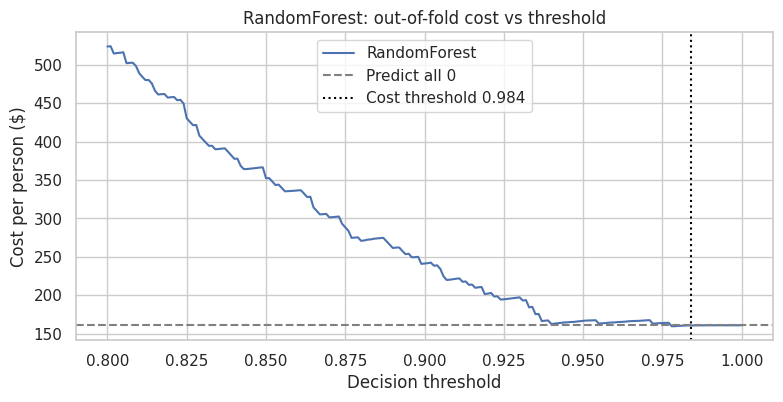

In [231]:
plt.figure(figsize=(9, 4))
plt.plot(thresholds, oof_costs, label=MODEL_NAME)
plt.axhline(BASELINE_PP, ls='--', c='grey', label='Predict all 0')
plt.axvline(THRESHOLD, ls=':', c='black', label=f'Cost threshold {THRESHOLD:.3f}')
plt.xlabel('Decision threshold'); plt.ylabel('Cost per person ($)')
plt.title(f'{MODEL_NAME}: out-of-fold cost vs threshold'); plt.legend(); plt.show()

In [232]:
# Respondents above the cost threshold, and how many of them are really vaccinated
sure = oof >= THRESHOLD
print(f'Predicted 1: {sure.sum()} of {len(oof)}')
if sure.any():
    print(f'Share truly vaccinated among them: {y_dev[sure].mean():.3f}  (needs to be above {THRESHOLD:.3f})')
print(f'OOF cost per person: ${cost_per_person(y_dev, sure.astype(int)):.2f}  vs baseline ${BASELINE_PP:.2f}')

Predicted 1: 3 of 3804
Share truly vaccinated among them: 1.000  (needs to be above 0.984)
OOF cost per person: $160.65  vs baseline $160.88


### Repeated cross-validation (robustness)
5-fold CV repeated 3 times (15 fits) at the cost threshold, to measure how much the cost varies from one data split to another.

In [233]:
rcv = evaluate_cv(tuned_model, X_dev, y_dev, cv=RCV)
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
rcv['baseline_pp'] = baseline_folds
rcv['saving_pp'] = rcv['baseline_pp'] - rcv['cost_pp']
rcv.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,cost_pp,auc,log_loss,baseline_pp,saving_pp
mean,160.673,0.847,0.487,160.883,0.210
std,0.317,0.013,0.016,0.088,0.293
min,160.053,0.835,0.440,160.841,0.000
max,161.053,0.886,0.501,161.053,0.788


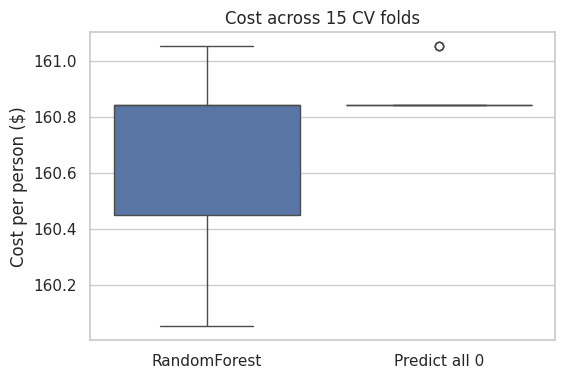

In [234]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=rcv[['cost_pp', 'baseline_pp']].rename(
    columns={'cost_pp': MODEL_NAME, 'baseline_pp': 'Predict all 0'}))
plt.ylabel('Cost per person ($)'); plt.title('Cost across 15 CV folds'); plt.show()

In [235]:
print(f'Mean saving vs baseline: ${rcv.saving_pp.mean():.2f} per person '
      f'(folds where the model beats or matches the baseline: {(rcv.saving_pp >= 0).mean():.0%})')

Mean saving vs baseline: $0.21 per person (folds where the model beats or matches the baseline: 100%)


### Hold-out validation (unseen data)
Fit on the full development set and score once on the 20% hold-out set.

In [236]:
dev_model = clone(tuned_model).fit(X_dev, y_dev)
p_hold = dev_model.predict_proba(X_hold)[:, 1]
pred_hold = (p_hold >= THRESHOLD).astype(int)
hold_baseline = cost_per_person(y_hold, np.zeros(len(y_hold)))

In [237]:
print(f'Hold-out AUC: {roc_auc_score(y_hold, p_hold):.4f}')
print(f'Hold-out cost per person: ${cost_per_person(y_hold, pred_hold):.2f}  (baseline ${hold_baseline:.2f})')
print(f'Hold-out total cost: ${total_cost(y_hold, pred_hold):,}   predicted 1: {pred_hold.sum()}')

Hold-out AUC: 0.8447
Hold-out cost per person: $161.03  (baseline $161.03)
Hold-out total cost: $153,300   predicted 1: 0


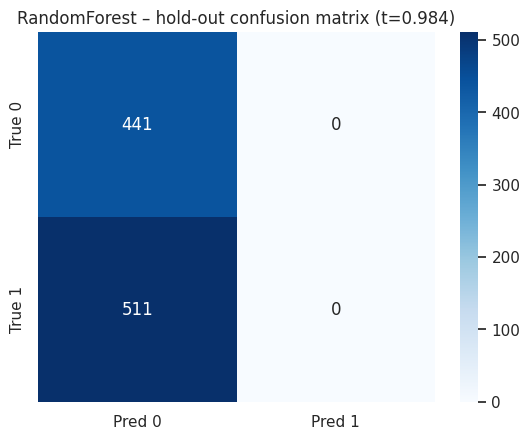

In [238]:
cm = confusion_matrix(y_hold, pred_hold, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
plt.title(f'{MODEL_NAME} – hold-out confusion matrix (t={THRESHOLD:.3f})'); plt.show()

In [239]:
# The same model at the default 0.5 threshold, for contrast
pred_05 = (p_hold >= 0.5).astype(int)
for name, pred in {'t=0.5': pred_05, f't={THRESHOLD:.3f}': pred_hold}.items():
    print(f'{name:8s} accuracy={(pred == y_hold).mean():.3f}  cost per person=${cost_per_person(y_hold, pred):,.2f}')

t=0.5    accuracy=0.773  cost per person=$2,228.36
t=0.984  accuracy=0.463  cost per person=$161.03


### Explaining the model

#### Impurity-based feature importance
How much each encoded feature reduces impurity across all trees.

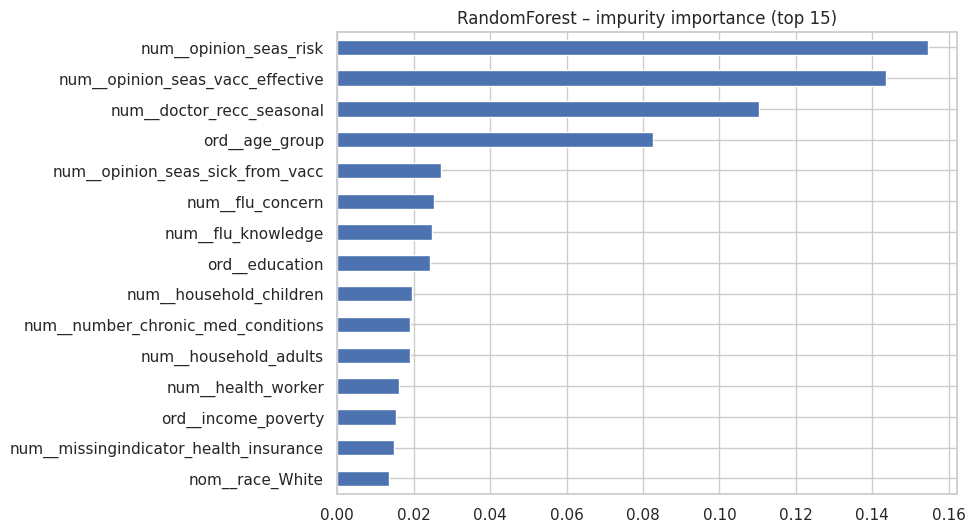

In [240]:
feat_names = dev_model.named_steps['prep'].get_feature_names_out()
imp = pd.Series(dev_model.named_steps['model'].feature_importances_, index=feat_names)
imp.sort_values().tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – impurity importance (top 15)'); plt.show()

#### Permutation importance on the hold-out set
Model-agnostic: how much hold-out log loss gets worse when one original feature is shuffled.

In [241]:
perm = permutation_importance(dev_model, X_hold, y_hold, scoring='neg_log_loss',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

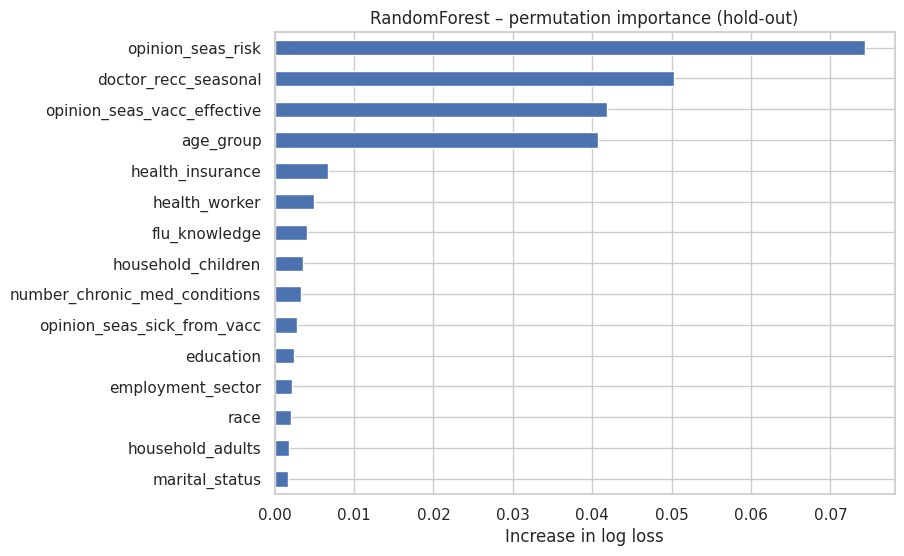

In [242]:
perm_imp.tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – permutation importance (hold-out)'); plt.xlabel('Increase in log loss')
plt.show()

#### Summary of findings – Random Forest
- **Pre-processing:** Option B (missing-aware) gives the better log loss and AUC.
- **Tuning:** 500 trees, `max_depth = 10`, `max_features = 0.3`. Limiting depth stops individual trees memorising respondents.
- **Cost:** it flags only 3 out-of-fold respondents above the threshold, all truly vaccinated. It saves about **\$0.21 per person** on average and never does worse than the baseline across the 15 folds.
- **Hold-out:** it flags nobody, so it costs the same as the baseline (\$161.03). It is the most cautious of the five models, which is safe but saves the least money.
- **Drivers:** perceived risk, doctor recommendation, opinion on vaccine effectiveness and age.

### Save results and test predictions
- `results/<model>_results.json` holds the numbers used by Section 11.
- `results/<model>_holdout_proba.csv` holds hold-out probabilities (used for the cost sensitivity analysis).
- `results/<model>_test_predictions.csv` holds test-set predictions from the model refitted on **all** labelled data.

In [243]:
os.makedirs('results', exist_ok=True)
results = {
    'model': MODEL_NAME,
    'preprocessing': BEST_PREP_NAME,
    'best_params': {k: str(v) for k, v in search.best_params_.items()},
    'cv_log_loss': float(-search.best_score_),
    'rcv_cost_pp_folds': rcv['cost_pp'].round(4).tolist(),
    'rcv_cost_pp_mean': float(rcv['cost_pp'].mean()),
    'rcv_cost_pp_std': float(rcv['cost_pp'].std()),
    'rcv_auc_mean': float(rcv['auc'].mean()),
    'holdout_cost_pp': float(cost_per_person(y_hold, pred_hold)),
    'holdout_cost_pp_t05': float(cost_per_person(y_hold, pred_05)),
    'holdout_auc': float(roc_auc_score(y_hold, p_hold)),
}

In [244]:
with open(f'results/{MODEL_NAME}_results.json', 'w') as f:
    json.dump(results, f, indent=2)
pd.DataFrame({'p': p_hold}, index=X_hold.index).to_csv(f'results/{MODEL_NAME}_holdout_proba.csv')

In [245]:
# Refit on all labelled data (development + hold-out) and predict the test set
final_model = clone(tuned_model).fit(X, y)
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
sub = pd.DataFrame({'respondent_id': test['respondent_id'], TARGET: (p_test >= THRESHOLD).astype(int)})
sub.to_csv(f'results/{MODEL_NAME}_test_predictions.csv', index=False)
print(f'Test respondents predicted as vaccinated: {sub[TARGET].sum()}')

Test respondents predicted as vaccinated: 0


## 8. Neural Network (MLP)

### Why this model
A multi-layer perceptron learns non-linear combinations of the features through hidden layers.
Weight decay (`alpha`, L2) and early stopping stop it overfitting on this fairly small data set (about 3,800 training rows).
Inputs are standardised by the pre-processor, which neural networks need.

In [246]:
from sklearn.neural_network import MLPClassifier

MODEL_NAME = 'NeuralNet'
base_model = MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=1000, early_stopping=True, random_state=RANDOM_STATE)

#### Pre-processing option A vs option B
Untuned model, 5-fold CV on the development set.

In [247]:
prep_results = []
for prep_name, prep in {'A_simple': prep_A, 'B_missing_aware': prep_B}.items():
    res = evaluate_cv(make_pipe(prep, base_model), X_dev, y_dev)
    res['prep'] = prep_name
    prep_results.append(res)
prep_results = pd.concat(prep_results, ignore_index=True)

In [248]:
prep_results.groupby('prep').agg(['mean', 'std']).round(4)

cost_pp             auc         log_loss        
                     mean     std    mean     std     mean     std
prep                                                              
A_simple         160.7256  0.3873  0.8349  0.0130   0.5025  0.0162
B_missing_aware  160.4889  0.3504  0.8378  0.0134   0.5004  0.0184

In [249]:
# Choose the option with the lower log loss (better probabilities) for tuning
prep_ll = prep_results.groupby('prep')['log_loss'].mean()
BEST_PREP_NAME = prep_ll.idxmin()
best_prep = {'A_simple': prep_A, 'B_missing_aware': prep_B}[BEST_PREP_NAME]
print('Pre-processing used from here on:', BEST_PREP_NAME)

Pre-processing used from here on: B_missing_aware


### Hyper-parameter tuning
`RandomizedSearchCV` with 5-fold CV, scored on **log loss**. Log loss is a smooth measure of probability quality, and the cost decision depends on
reliable probabilities. Cost itself only changes when a respondent crosses the 0.984 threshold, so it is too noisy to tune on directly.

In [250]:
param_grid = {'model__hidden_layer_sizes': [(16,), (32,), (64,), (32, 16)],
        'model__alpha': np.logspace(-2, 1.5, 10),        # L2 weight decay
        'model__learning_rate_init': [0.001, 0.003]}

In [251]:
search = RandomizedSearchCV(make_pipe(best_prep, base_model), param_grid, n_iter=20,
                            cv=CV, scoring='neg_log_loss', random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_dev, y_dev)
tuned_model = search.best_estimator_
print('Best CV log loss:', round(-search.best_score_, 4))
print('Best parameters:', search.best_params_)

Best CV log loss: 0.4894
Best parameters: {'model__learning_rate_init': 0.003, 'model__hidden_layer_sizes': (32, 16), 'model__alpha': np.float64(2.1544346900318843)}


In [252]:
# Top 5 parameter combinations tried
cv_res = pd.DataFrame(search.cv_results_)
cv_res['log_loss'] = -cv_res['mean_test_score']
cv_res.sort_values('log_loss')[['params', 'log_loss', 'std_test_score']].head(5)

,params,log_loss,std_test_score
18,"{'model__learning_rate_init': 0.003, 'model__h...",0.489392,0.005986
17,"{'model__learning_rate_init': 0.003, 'model__h...",0.492990,0.008838
11,"{'model__learning_rate_init': 0.003, 'model__h...",0.494395,0.009104
3,"{'model__learning_rate_init': 0.003, 'model__h...",0.494410,0.006543
0,"{'model__learning_rate_init': 0.001, 'model__h...",0.495355,0.006341


### Cost against decision threshold
Out-of-fold probabilities (each respondent is predicted by a model that did not train on them), then the cost of every threshold.

In [253]:
oof = cross_val_predict(tuned_model, X_dev, y_dev, cv=CV, method='predict_proba')[:, 1]
thresholds = np.linspace(0.80, 1.0, 201)
oof_costs = [cost_per_person(y_dev, (oof >= t).astype(int)) for t in thresholds]
print(f'OOF AUC {roc_auc_score(y_dev, oof):.4f} | OOF log loss {log_loss(y_dev, oof):.4f}')

OOF AUC 0.8450 | OOF log loss 0.4894


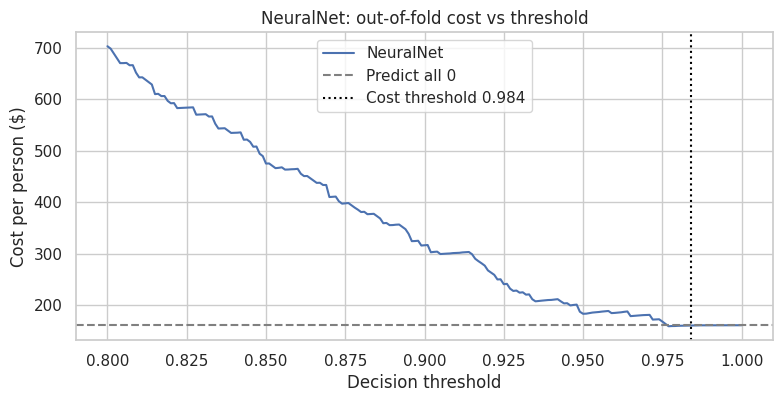

In [254]:
plt.figure(figsize=(9, 4))
plt.plot(thresholds, oof_costs, label=MODEL_NAME)
plt.axhline(BASELINE_PP, ls='--', c='grey', label='Predict all 0')
plt.axvline(THRESHOLD, ls=':', c='black', label=f'Cost threshold {THRESHOLD:.3f}')
plt.xlabel('Decision threshold'); plt.ylabel('Cost per person ($)')
plt.title(f'{MODEL_NAME}: out-of-fold cost vs threshold'); plt.legend(); plt.show()

In [255]:
# Respondents above the cost threshold, and how many of them are really vaccinated
sure = oof >= THRESHOLD
print(f'Predicted 1: {sure.sum()} of {len(oof)}')
if sure.any():
    print(f'Share truly vaccinated among them: {y_dev[sure].mean():.3f}  (needs to be above {THRESHOLD:.3f})')
print(f'OOF cost per person: ${cost_per_person(y_dev, sure.astype(int)):.2f}  vs baseline ${BASELINE_PP:.2f}')

Predicted 1: 6 of 3804
Share truly vaccinated among them: 1.000  (needs to be above 0.984)
OOF cost per person: $160.41  vs baseline $160.88


### Repeated cross-validation (robustness)
5-fold CV repeated 3 times (15 fits) at the cost threshold, to measure how much the cost varies from one data split to another.

In [256]:
rcv = evaluate_cv(tuned_model, X_dev, y_dev, cv=RCV)
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
rcv['baseline_pp'] = baseline_folds
rcv['saving_pp'] = rcv['baseline_pp'] - rcv['cost_pp']
rcv.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,cost_pp,auc,log_loss,baseline_pp,saving_pp
mean,160.594,0.846,0.489,160.883,0.289
std,0.363,0.015,0.020,0.088,0.348
min,159.658,0.821,0.438,160.841,0.000
max,161.053,0.885,0.526,161.053,1.183


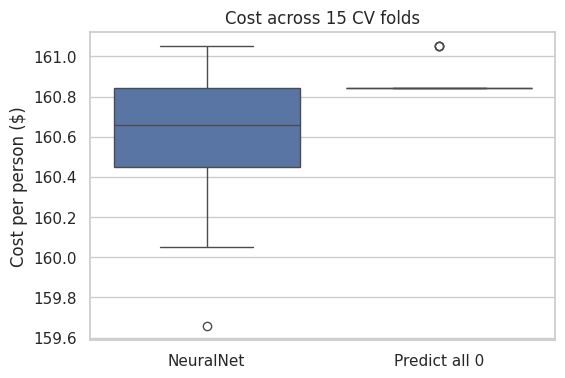

In [257]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=rcv[['cost_pp', 'baseline_pp']].rename(
    columns={'cost_pp': MODEL_NAME, 'baseline_pp': 'Predict all 0'}))
plt.ylabel('Cost per person ($)'); plt.title('Cost across 15 CV folds'); plt.show()

In [258]:
print(f'Mean saving vs baseline: ${rcv.saving_pp.mean():.2f} per person '
      f'(folds where the model beats or matches the baseline: {(rcv.saving_pp >= 0).mean():.0%})')

Mean saving vs baseline: $0.29 per person (folds where the model beats or matches the baseline: 100%)


### Hold-out validation (unseen data)
Fit on the full development set and score once on the 20% hold-out set.

In [259]:
dev_model = clone(tuned_model).fit(X_dev, y_dev)
p_hold = dev_model.predict_proba(X_hold)[:, 1]
pred_hold = (p_hold >= THRESHOLD).astype(int)
hold_baseline = cost_per_person(y_hold, np.zeros(len(y_hold)))

In [260]:
print(f'Hold-out AUC: {roc_auc_score(y_hold, p_hold):.4f}')
print(f'Hold-out cost per person: ${cost_per_person(y_hold, pred_hold):.2f}  (baseline ${hold_baseline:.2f})')
print(f'Hold-out total cost: ${total_cost(y_hold, pred_hold):,}   predicted 1: {pred_hold.sum()}')

Hold-out AUC: 0.8503
Hold-out cost per person: $160.71  (baseline $161.03)
Hold-out total cost: $153,000   predicted 1: 1


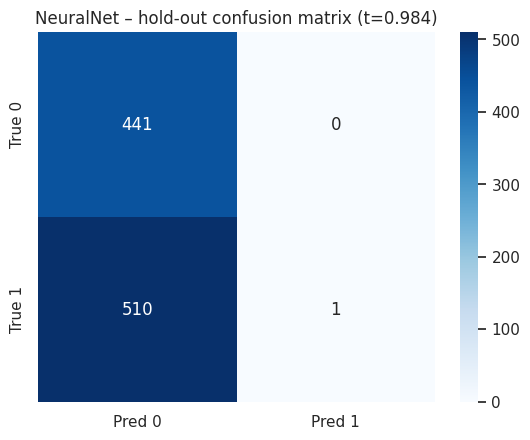

In [261]:
cm = confusion_matrix(y_hold, pred_hold, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
plt.title(f'{MODEL_NAME} – hold-out confusion matrix (t={THRESHOLD:.3f})'); plt.show()

In [262]:
# The same model at the default 0.5 threshold, for contrast
pred_05 = (p_hold >= 0.5).astype(int)
for name, pred in {'t=0.5': pred_05, f't={THRESHOLD:.3f}': pred_hold}.items():
    print(f'{name:8s} accuracy={(pred == y_hold).mean():.3f}  cost per person=${cost_per_person(y_hold, pred):,.2f}')

t=0.5    accuracy=0.771  cost per person=$2,305.46
t=0.984  accuracy=0.464  cost per person=$160.71


### Explaining the model

#### Permutation importance on the hold-out set
Model-agnostic: how much hold-out log loss gets worse when one original feature is shuffled.

In [263]:
perm = permutation_importance(dev_model, X_hold, y_hold, scoring='neg_log_loss',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

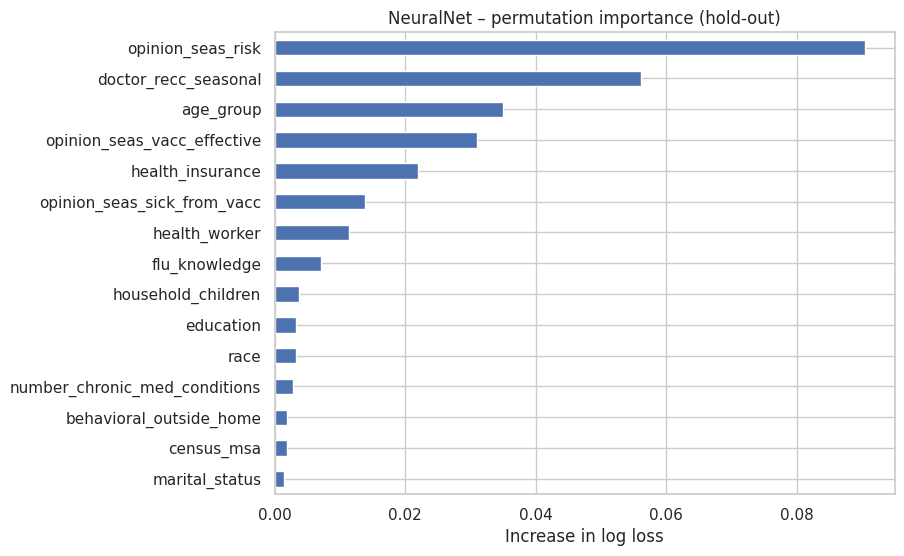

In [264]:
perm_imp.tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – permutation importance (hold-out)'); plt.xlabel('Increase in log loss')
plt.show()

#### Summary of findings – Neural Network
- **Pre-processing:** Option B (missing-aware) gives the better log loss.
- **Tuning:** two hidden layers (32, 16) with strong weight decay (`alpha` ≈ 2.2). Heavy regularisation stops the network becoming overconfident on such a small data set.
- **Cost:** it flags 6 out-of-fold respondents, all truly vaccinated. It saves about **\$0.29 per person** on average and beats or matches the baseline on every fold.
- **Hold-out:** \$160.71 per person against \$161.03 for the baseline.
- **Drivers:** the same as the other models (perceived risk, doctor recommendation, age, vaccine effectiveness). The network has not learnt anything unexpected.

### Save results and test predictions
- `results/<model>_results.json` holds the numbers used by Section 11.
- `results/<model>_holdout_proba.csv` holds hold-out probabilities (used for the cost sensitivity analysis).
- `results/<model>_test_predictions.csv` holds test-set predictions from the model refitted on **all** labelled data.

In [265]:
os.makedirs('results', exist_ok=True)
results = {
    'model': MODEL_NAME,
    'preprocessing': BEST_PREP_NAME,
    'best_params': {k: str(v) for k, v in search.best_params_.items()},
    'cv_log_loss': float(-search.best_score_),
    'rcv_cost_pp_folds': rcv['cost_pp'].round(4).tolist(),
    'rcv_cost_pp_mean': float(rcv['cost_pp'].mean()),
    'rcv_cost_pp_std': float(rcv['cost_pp'].std()),
    'rcv_auc_mean': float(rcv['auc'].mean()),
    'holdout_cost_pp': float(cost_per_person(y_hold, pred_hold)),
    'holdout_cost_pp_t05': float(cost_per_person(y_hold, pred_05)),
    'holdout_auc': float(roc_auc_score(y_hold, p_hold)),
}

In [266]:
with open(f'results/{MODEL_NAME}_results.json', 'w') as f:
    json.dump(results, f, indent=2)
pd.DataFrame({'p': p_hold}, index=X_hold.index).to_csv(f'results/{MODEL_NAME}_holdout_proba.csv')

In [267]:
# Refit on all labelled data (development + hold-out) and predict the test set
final_model = clone(tuned_model).fit(X, y)
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
sub = pd.DataFrame({'respondent_id': test['respondent_id'], TARGET: (p_test >= THRESHOLD).astype(int)})
sub.to_csv(f'results/{MODEL_NAME}_test_predictions.csv', index=False)
print(f'Test respondents predicted as vaccinated: {sub[TARGET].sum()}')

Test respondents predicted as vaccinated: 5


## 9. Extra Trees

### Why this model
Extra Trees is like a random forest, but it picks split thresholds at random instead of searching for the best one.
This extra randomness makes the trees more different from each other, so their average is smoother and less overconfident.
That suits our cost metric, which punishes a confident wrong "vaccinated" prediction very heavily.

In [268]:
from sklearn.ensemble import ExtraTreesClassifier

MODEL_NAME = 'ExtraTrees'
base_model = ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

#### Pre-processing option A vs option B
Untuned model, 5-fold CV on the development set.

In [269]:
prep_results = []
for prep_name, prep in {'A_simple': prep_A, 'B_missing_aware': prep_B}.items():
    res = evaluate_cv(make_pipe(prep, base_model), X_dev, y_dev)
    res['prep'] = prep_name
    prep_results.append(res)
prep_results = pd.concat(prep_results, ignore_index=True)

In [270]:
prep_results.groupby('prep').agg(['mean', 'std']).round(4)

cost_pp              auc         log_loss        
                     mean      std    mean     std     mean     std
prep                                                               
A_simple         164.0893  10.9036  0.8269  0.0143   0.5320  0.0210
B_missing_aware  158.8329   0.7171  0.8404  0.0070   0.5005  0.0096

In [271]:
# Choose the option with the lower log loss (better probabilities) for tuning
prep_ll = prep_results.groupby('prep')['log_loss'].mean()
BEST_PREP_NAME = prep_ll.idxmin()
best_prep = {'A_simple': prep_A, 'B_missing_aware': prep_B}[BEST_PREP_NAME]
print('Pre-processing used from here on:', BEST_PREP_NAME)

Pre-processing used from here on: B_missing_aware


### Hyper-parameter tuning
`RandomizedSearchCV` with 5-fold CV, scored on **log loss**. Log loss is a smooth measure of probability quality, and the cost decision depends on
reliable probabilities. Cost itself only changes when a respondent crosses the 0.984 threshold, so it is too noisy to tune on directly.

In [272]:
param_grid = {'model__n_estimators': [300, 500],
        'model__max_depth': [8, 12, None],
        'model__min_samples_leaf': [1, 3, 5, 10],
        'model__max_features': ['sqrt', 0.3, 0.5]}

In [273]:
search = RandomizedSearchCV(make_pipe(best_prep, base_model), param_grid, n_iter=15,
                            cv=CV, scoring='neg_log_loss', random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_dev, y_dev)
tuned_model = search.best_estimator_
print('Best CV log loss:', round(-search.best_score_, 4))
print('Best parameters:', search.best_params_)

Best CV log loss: 0.487
Best parameters: {'model__n_estimators': 300, 'model__min_samples_leaf': 3, 'model__max_features': 0.3, 'model__max_depth': 12}


In [274]:
# Top 5 parameter combinations tried
cv_res = pd.DataFrame(search.cv_results_)
cv_res['log_loss'] = -cv_res['mean_test_score']
cv_res.sort_values('log_loss')[['params', 'log_loss', 'std_test_score']].head(5)

,params,log_loss,std_test_score
7,"{'model__n_estimators': 300, 'model__min_sampl...",0.486972,0.009249
13,"{'model__n_estimators': 500, 'model__min_sampl...",0.487703,0.009477
10,"{'model__n_estimators': 500, 'model__min_sampl...",0.490117,0.009394
2,"{'model__n_estimators': 300, 'model__min_sampl...",0.490133,0.006892
1,"{'model__n_estimators': 300, 'model__min_sampl...",0.492059,0.009201


### Cost against decision threshold
Out-of-fold probabilities (each respondent is predicted by a model that did not train on them), then the cost of every threshold.

In [275]:
oof = cross_val_predict(tuned_model, X_dev, y_dev, cv=CV, method='predict_proba')[:, 1]
thresholds = np.linspace(0.80, 1.0, 201)
oof_costs = [cost_per_person(y_dev, (oof >= t).astype(int)) for t in thresholds]
print(f'OOF AUC {roc_auc_score(y_dev, oof):.4f} | OOF log loss {log_loss(y_dev, oof):.4f}')

OOF AUC 0.8478 | OOF log loss 0.4870


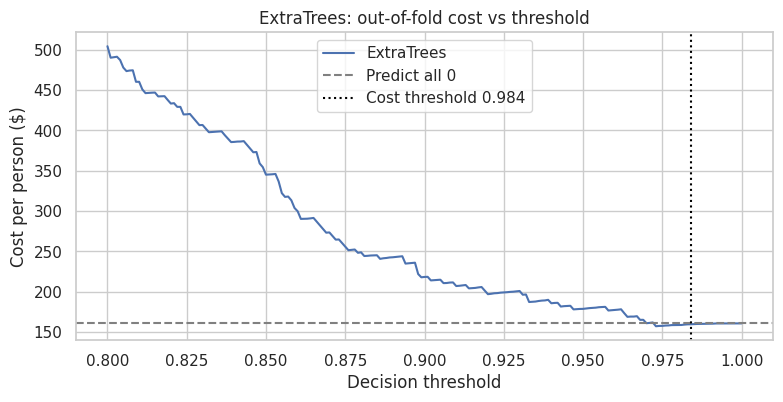

In [276]:
plt.figure(figsize=(9, 4))
plt.plot(thresholds, oof_costs, label=MODEL_NAME)
plt.axhline(BASELINE_PP, ls='--', c='grey', label='Predict all 0')
plt.axvline(THRESHOLD, ls=':', c='black', label=f'Cost threshold {THRESHOLD:.3f}')
plt.xlabel('Decision threshold'); plt.ylabel('Cost per person ($)')
plt.title(f'{MODEL_NAME}: out-of-fold cost vs threshold'); plt.legend(); plt.show()

In [277]:
# Respondents above the cost threshold, and how many of them are really vaccinated
sure = oof >= THRESHOLD
print(f'Predicted 1: {sure.sum()} of {len(oof)}')
if sure.any():
    print(f'Share truly vaccinated among them: {y_dev[sure].mean():.3f}  (needs to be above {THRESHOLD:.3f})')
print(f'OOF cost per person: ${cost_per_person(y_dev, sure.astype(int)):.2f}  vs baseline ${BASELINE_PP:.2f}')

Predicted 1: 14 of 3804
Share truly vaccinated among them: 1.000  (needs to be above 0.984)
OOF cost per person: $159.78  vs baseline $160.88


### Repeated cross-validation (robustness)
5-fold CV repeated 3 times (15 fits) at the cost threshold, to measure how much the cost varies from one data split to another.

In [278]:
rcv = evaluate_cv(tuned_model, X_dev, y_dev, cv=RCV)
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
rcv['baseline_pp'] = baseline_folds
rcv['saving_pp'] = rcv['baseline_pp'] - rcv['cost_pp']
rcv.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,cost_pp,auc,log_loss,baseline_pp,saving_pp
mean,159.674,0.848,0.488,160.883,1.209
std,0.683,0.013,0.015,0.088,0.657
min,158.476,0.836,0.442,160.841,0.000
max,161.053,0.886,0.502,161.053,2.365


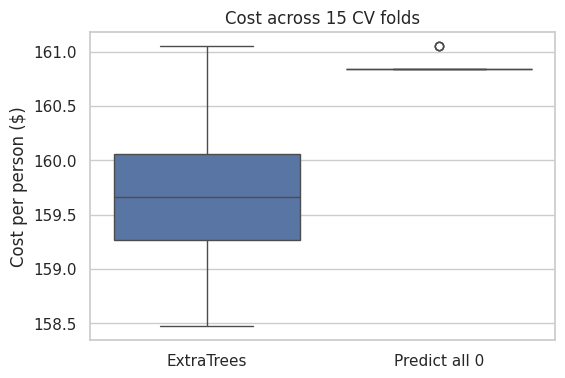

In [279]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=rcv[['cost_pp', 'baseline_pp']].rename(
    columns={'cost_pp': MODEL_NAME, 'baseline_pp': 'Predict all 0'}))
plt.ylabel('Cost per person ($)'); plt.title('Cost across 15 CV folds'); plt.show()

In [280]:
print(f'Mean saving vs baseline: ${rcv.saving_pp.mean():.2f} per person '
      f'(folds where the model beats or matches the baseline: {(rcv.saving_pp >= 0).mean():.0%})')

Mean saving vs baseline: $1.21 per person (folds where the model beats or matches the baseline: 100%)


### Hold-out validation (unseen data)
Fit on the full development set and score once on the 20% hold-out set.

In [281]:
dev_model = clone(tuned_model).fit(X_dev, y_dev)
p_hold = dev_model.predict_proba(X_hold)[:, 1]
pred_hold = (p_hold >= THRESHOLD).astype(int)
hold_baseline = cost_per_person(y_hold, np.zeros(len(y_hold)))

In [282]:
print(f'Hold-out AUC: {roc_auc_score(y_hold, p_hold):.4f}')
print(f'Hold-out cost per person: ${cost_per_person(y_hold, pred_hold):.2f}  (baseline ${hold_baseline:.2f})')
print(f'Hold-out total cost: ${total_cost(y_hold, pred_hold):,}   predicted 1: {pred_hold.sum()}')

Hold-out AUC: 0.8435
Hold-out cost per person: $160.71  (baseline $161.03)
Hold-out total cost: $153,000   predicted 1: 1


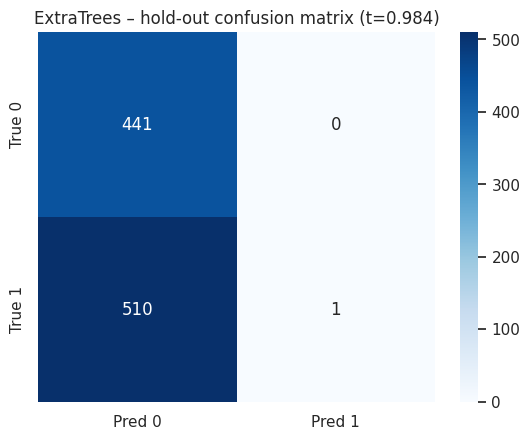

In [283]:
cm = confusion_matrix(y_hold, pred_hold, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
plt.title(f'{MODEL_NAME} – hold-out confusion matrix (t={THRESHOLD:.3f})'); plt.show()

In [284]:
# The same model at the default 0.5 threshold, for contrast
pred_05 = (p_hold >= 0.5).astype(int)
for name, pred in {'t=0.5': pred_05, f't={THRESHOLD:.3f}': pred_hold}.items():
    print(f'{name:8s} accuracy={(pred == y_hold).mean():.3f}  cost per person=${cost_per_person(y_hold, pred):,.2f}')

t=0.5    accuracy=0.775  cost per person=$2,036.55
t=0.984  accuracy=0.464  cost per person=$160.71


### Explaining the model

#### Impurity-based feature importance
How much each encoded feature reduces impurity across all trees.

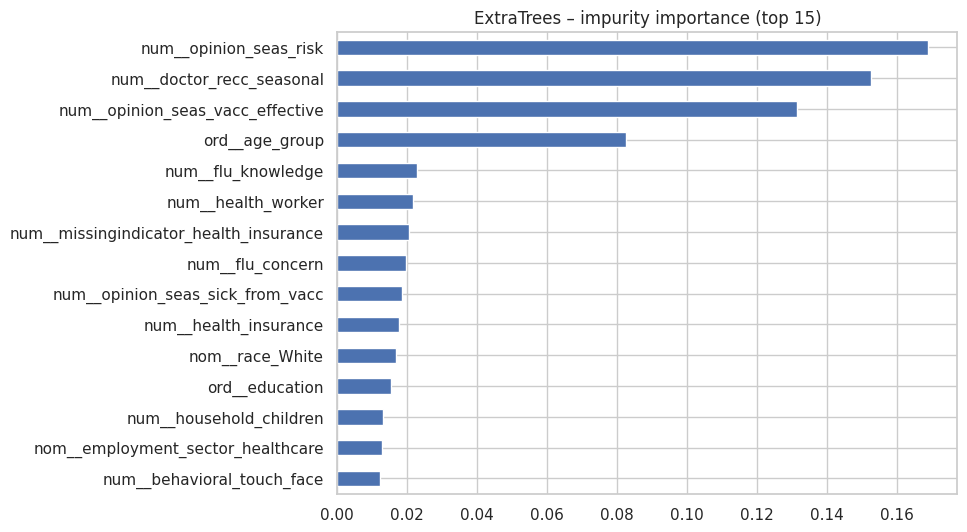

In [285]:
feat_names = dev_model.named_steps['prep'].get_feature_names_out()
imp = pd.Series(dev_model.named_steps['model'].feature_importances_, index=feat_names)
imp.sort_values().tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – impurity importance (top 15)'); plt.show()

#### Permutation importance on the hold-out set
Model-agnostic: how much hold-out log loss gets worse when one original feature is shuffled.

In [286]:
perm = permutation_importance(dev_model, X_hold, y_hold, scoring='neg_log_loss',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

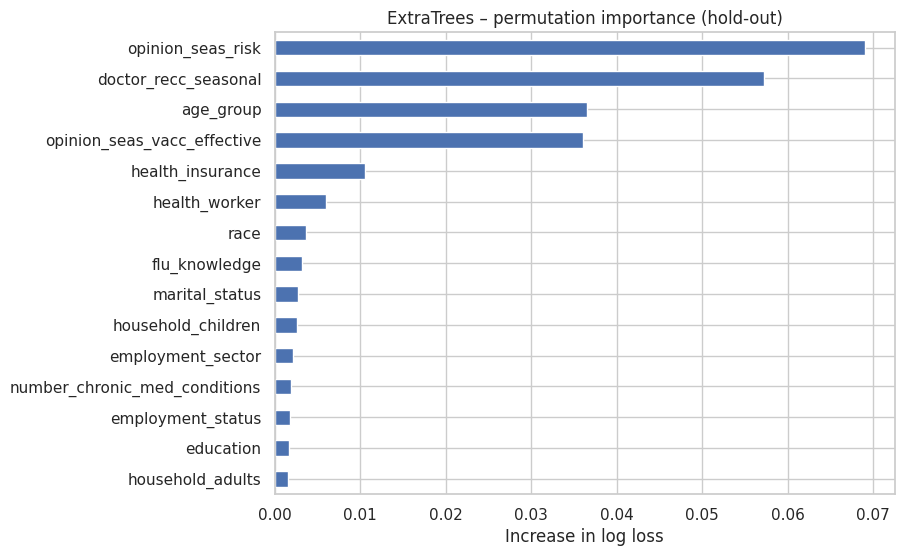

In [287]:
perm_imp.tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – permutation importance (hold-out)'); plt.xlabel('Increase in log loss')
plt.show()

#### Summary of findings – Extra Trees
- **Pre-processing:** Option B (missing-aware) is clearly better here: lower log loss, higher AUC and much more stable cost than Option A.
- **Tuning:** 300 trees, `max_depth = 12`, `min_samples_leaf = 3`, `max_features = 0.3`.
- **Cost:** it flags **14** out-of-fold respondents above the threshold, the most of any model, and **all 14 are truly vaccinated**. It saves about **\$1.21 per person**,
  the largest saving of the five models, and it beats or matches the baseline on every fold.
- **Hold-out:** \$160.71 per person against \$161.03 for the baseline.
- **Why it works:** the random split thresholds make the trees very different from each other, so the averaged probability only gets close to 1 when almost every tree agrees. That is exactly the kind of confidence the cost metric rewards.

### Save results and test predictions
- `results/<model>_results.json` holds the numbers used by Section 11.
- `results/<model>_holdout_proba.csv` holds hold-out probabilities (used for the cost sensitivity analysis).
- `results/<model>_test_predictions.csv` holds test-set predictions from the model refitted on **all** labelled data.

In [288]:
os.makedirs('results', exist_ok=True)
results = {
    'model': MODEL_NAME,
    'preprocessing': BEST_PREP_NAME,
    'best_params': {k: str(v) for k, v in search.best_params_.items()},
    'cv_log_loss': float(-search.best_score_),
    'rcv_cost_pp_folds': rcv['cost_pp'].round(4).tolist(),
    'rcv_cost_pp_mean': float(rcv['cost_pp'].mean()),
    'rcv_cost_pp_std': float(rcv['cost_pp'].std()),
    'rcv_auc_mean': float(rcv['auc'].mean()),
    'holdout_cost_pp': float(cost_per_person(y_hold, pred_hold)),
    'holdout_cost_pp_t05': float(cost_per_person(y_hold, pred_05)),
    'holdout_auc': float(roc_auc_score(y_hold, p_hold)),
}

In [289]:
with open(f'results/{MODEL_NAME}_results.json', 'w') as f:
    json.dump(results, f, indent=2)
pd.DataFrame({'p': p_hold}, index=X_hold.index).to_csv(f'results/{MODEL_NAME}_holdout_proba.csv')

In [290]:
# Refit on all labelled data (development + hold-out) and predict the test set
final_model = clone(tuned_model).fit(X, y)
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
sub = pd.DataFrame({'respondent_id': test['respondent_id'], TARGET: (p_test >= THRESHOLD).astype(int)})
sub.to_csv(f'results/{MODEL_NAME}_test_predictions.csv', index=False)
print(f'Test respondents predicted as vaccinated: {sub[TARGET].sum()}')

Test respondents predicted as vaccinated: 10


## 10. Support Vector Machine (RBF)

### Why this model
A support vector machine with an RBF kernel finds a flexible, maximum-margin boundary between vaccinated and unvaccinated respondents.
SVMs do not output probabilities directly, so `probability=True` uses **Platt scaling**: a logistic curve fitted on internal cross-validation folds
that turns SVM scores into probabilities. `C` controls the margin softness and `gamma` controls how flexible the boundary is.

In [291]:
from sklearn.svm import SVC

MODEL_NAME = 'SVM'
base_model = SVC(probability=True, random_state=RANDOM_STATE)

#### Pre-processing option A vs option B
Untuned model, 5-fold CV on the development set.

In [292]:
prep_results = []
for prep_name, prep in {'A_simple': prep_A, 'B_missing_aware': prep_B}.items():
    res = evaluate_cv(make_pipe(prep, base_model), X_dev, y_dev)
    res['prep'] = prep_name
    prep_results.append(res)
prep_results = pd.concat(prep_results, ignore_index=True)

In [293]:
prep_results.groupby('prep').agg(['mean', 'std']).round(4)

cost_pp             auc         log_loss        
                     mean     std    mean     std     mean     std
prep                                                              
A_simple         160.7255  0.1748  0.8381  0.0105   0.4975  0.0142
B_missing_aware  160.8833  0.0946  0.8432  0.0113   0.4906  0.0156

In [294]:
# Choose the option with the lower log loss (better probabilities) for tuning
prep_ll = prep_results.groupby('prep')['log_loss'].mean()
BEST_PREP_NAME = prep_ll.idxmin()
best_prep = {'A_simple': prep_A, 'B_missing_aware': prep_B}[BEST_PREP_NAME]
print('Pre-processing used from here on:', BEST_PREP_NAME)

Pre-processing used from here on: B_missing_aware


### Hyper-parameter tuning
`RandomizedSearchCV` with 5-fold CV, scored on **log loss**. Log loss is a smooth measure of probability quality, and the cost decision depends on
reliable probabilities. Cost itself only changes when a respondent crosses the 0.984 threshold, so it is too noisy to tune on directly.

In [295]:
param_grid = {'model__C': [0.1, 0.3, 1, 3],
        'model__gamma': ['scale', 0.003, 0.01, 0.03]}

In [296]:
search = RandomizedSearchCV(make_pipe(best_prep, base_model), param_grid, n_iter=15,
                            cv=CV, scoring='neg_log_loss', random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_dev, y_dev)
tuned_model = search.best_estimator_
print('Best CV log loss:', round(-search.best_score_, 4))
print('Best parameters:', search.best_params_)

Best CV log loss: 0.4875
Best parameters: {'model__gamma': 0.003, 'model__C': 3}


In [297]:
# Top 5 parameter combinations tried
cv_res = pd.DataFrame(search.cv_results_)
cv_res['log_loss'] = -cv_res['mean_test_score']
cv_res.sort_values('log_loss')[['params', 'log_loss', 'std_test_score']].head(5)

,params,log_loss,std_test_score
4,"{'model__gamma': 0.003, 'model__C': 3}",0.487544,0.011434
12,"{'model__gamma': 0.01, 'model__C': 1}",0.487844,0.012236
3,"{'model__gamma': 0.01, 'model__C': 3}",0.489999,0.013492
6,"{'model__gamma': 'scale', 'model__C': 1}",0.490563,0.013912
7,"{'model__gamma': 0.003, 'model__C': 1}",0.490676,0.013159


### Cost against decision threshold
Out-of-fold probabilities (each respondent is predicted by a model that did not train on them), then the cost of every threshold.

In [298]:
oof = cross_val_predict(tuned_model, X_dev, y_dev, cv=CV, method='predict_proba')[:, 1]
thresholds = np.linspace(0.80, 1.0, 201)
oof_costs = [cost_per_person(y_dev, (oof >= t).astype(int)) for t in thresholds]
print(f'OOF AUC {roc_auc_score(y_dev, oof):.4f} | OOF log loss {log_loss(y_dev, oof):.4f}')

OOF AUC 0.8466 | OOF log loss 0.4875


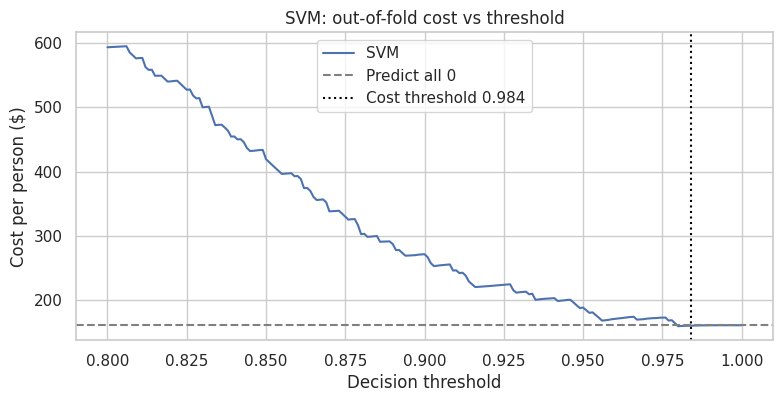

In [299]:
plt.figure(figsize=(9, 4))
plt.plot(thresholds, oof_costs, label=MODEL_NAME)
plt.axhline(BASELINE_PP, ls='--', c='grey', label='Predict all 0')
plt.axvline(THRESHOLD, ls=':', c='black', label=f'Cost threshold {THRESHOLD:.3f}')
plt.xlabel('Decision threshold'); plt.ylabel('Cost per person ($)')
plt.title(f'{MODEL_NAME}: out-of-fold cost vs threshold'); plt.legend(); plt.show()

In [300]:
# Respondents above the cost threshold, and how many of them are really vaccinated
sure = oof >= THRESHOLD
print(f'Predicted 1: {sure.sum()} of {len(oof)}')
if sure.any():
    print(f'Share truly vaccinated among them: {y_dev[sure].mean():.3f}  (needs to be above {THRESHOLD:.3f})')
print(f'OOF cost per person: ${cost_per_person(y_dev, sure.astype(int)):.2f}  vs baseline ${BASELINE_PP:.2f}')

Predicted 1: 7 of 3804
Share truly vaccinated among them: 1.000  (needs to be above 0.984)
OOF cost per person: $160.33  vs baseline $160.88


### Repeated cross-validation (robustness)
5-fold CV repeated 3 times (15 fits) at the cost threshold, to measure how much the cost varies from one data split to another.

In [301]:
rcv = evaluate_cv(tuned_model, X_dev, y_dev, cv=RCV)
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
rcv['baseline_pp'] = baseline_folds
rcv['saving_pp'] = rcv['baseline_pp'] - rcv['cost_pp']
rcv.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,cost_pp,auc,log_loss,baseline_pp,saving_pp
mean,160.252,0.848,0.487,160.883,0.631
std,0.519,0.015,0.020,0.088,0.490
min,159.264,0.828,0.432,160.841,0.000
max,161.053,0.890,0.514,161.053,1.577


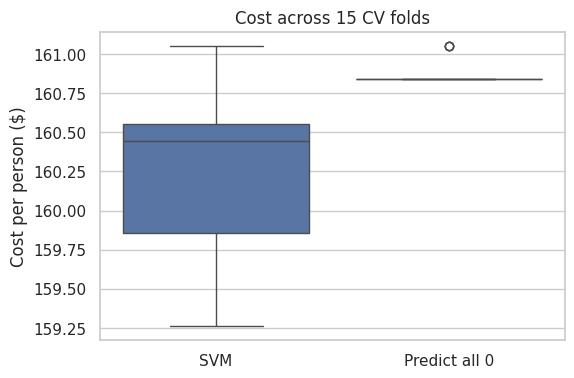

In [302]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=rcv[['cost_pp', 'baseline_pp']].rename(
    columns={'cost_pp': MODEL_NAME, 'baseline_pp': 'Predict all 0'}))
plt.ylabel('Cost per person ($)'); plt.title('Cost across 15 CV folds'); plt.show()

In [303]:
print(f'Mean saving vs baseline: ${rcv.saving_pp.mean():.2f} per person '
      f'(folds where the model beats or matches the baseline: {(rcv.saving_pp >= 0).mean():.0%})')

Mean saving vs baseline: $0.63 per person (folds where the model beats or matches the baseline: 100%)


### Hold-out validation (unseen data)
Fit on the full development set and score once on the 20% hold-out set.

In [304]:
dev_model = clone(tuned_model).fit(X_dev, y_dev)
p_hold = dev_model.predict_proba(X_hold)[:, 1]
pred_hold = (p_hold >= THRESHOLD).astype(int)
hold_baseline = cost_per_person(y_hold, np.zeros(len(y_hold)))

In [305]:
print(f'Hold-out AUC: {roc_auc_score(y_hold, p_hold):.4f}')
print(f'Hold-out cost per person: ${cost_per_person(y_hold, pred_hold):.2f}  (baseline ${hold_baseline:.2f})')
print(f'Hold-out total cost: ${total_cost(y_hold, pred_hold):,}   predicted 1: {pred_hold.sum()}')

Hold-out AUC: 0.8499
Hold-out cost per person: $160.40  (baseline $161.03)
Hold-out total cost: $152,700   predicted 1: 2


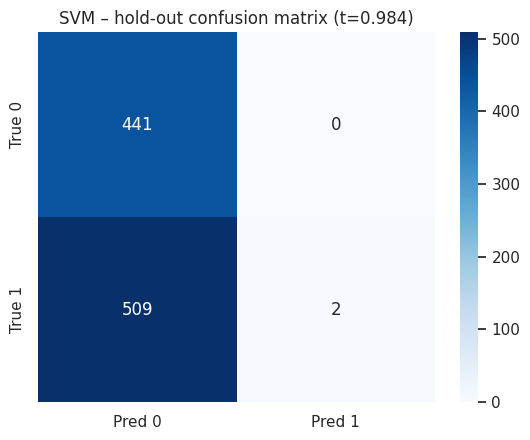

In [306]:
cm = confusion_matrix(y_hold, pred_hold, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
plt.title(f'{MODEL_NAME} – hold-out confusion matrix (t={THRESHOLD:.3f})'); plt.show()

In [307]:
# The same model at the default 0.5 threshold, for contrast
pred_05 = (p_hold >= 0.5).astype(int)
for name, pred in {'t=0.5': pred_05, f't={THRESHOLD:.3f}': pred_hold}.items():
    print(f'{name:8s} accuracy={(pred == y_hold).mean():.3f}  cost per person=${cost_per_person(y_hold, pred):,.2f}')

t=0.5    accuracy=0.778  cost per person=$2,226.79
t=0.984  accuracy=0.465  cost per person=$160.40


### Explaining the model

#### Permutation importance on the hold-out set
Model-agnostic: how much hold-out log loss gets worse when one original feature is shuffled.

In [308]:
perm = permutation_importance(dev_model, X_hold, y_hold, scoring='neg_log_loss',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

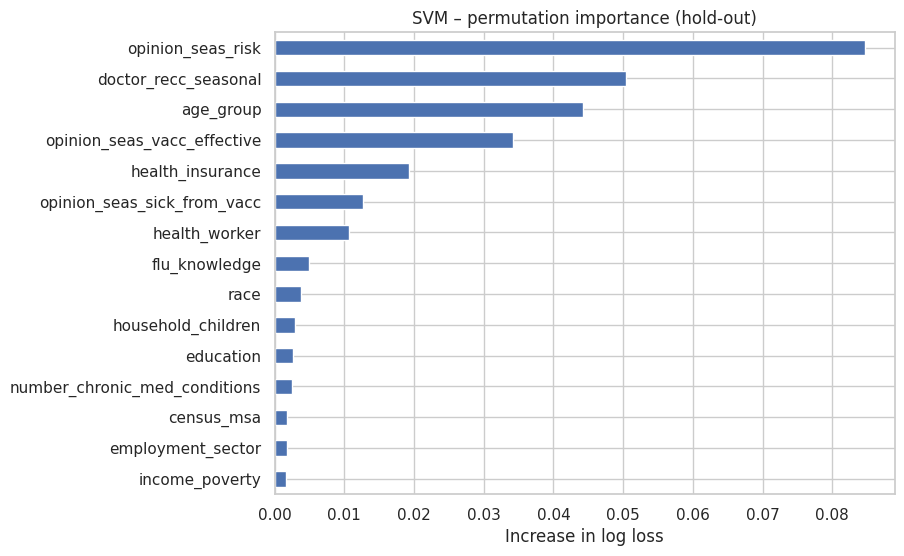

In [309]:
perm_imp.tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – permutation importance (hold-out)'); plt.xlabel('Increase in log loss')
plt.show()

#### Summary of findings – SVM
- **Pre-processing:** Option B (missing-aware) gives the better log loss.
- **Tuning:** `C = 3`, `gamma = 0.003`. The small gamma gives a smooth, nearly linear boundary.
- **Cost:** it flags 7 out-of-fold respondents, all truly vaccinated. It saves about **\$0.63 per person** on average and beats or matches the baseline on every fold.
- **Hold-out:** **\$160.40 per person, the cheapest of the five on the hold-out set** (2 correct "vaccinated" calls).
- **Drivers:** perceived risk, doctor recommendation, age and vaccine effectiveness, matching the other models.

### Save results and test predictions
- `results/<model>_results.json` holds the numbers used by Section 11.
- `results/<model>_holdout_proba.csv` holds hold-out probabilities (used for the cost sensitivity analysis).
- `results/<model>_test_predictions.csv` holds test-set predictions from the model refitted on **all** labelled data.

In [310]:
os.makedirs('results', exist_ok=True)
results = {
    'model': MODEL_NAME,
    'preprocessing': BEST_PREP_NAME,
    'best_params': {k: str(v) for k, v in search.best_params_.items()},
    'cv_log_loss': float(-search.best_score_),
    'rcv_cost_pp_folds': rcv['cost_pp'].round(4).tolist(),
    'rcv_cost_pp_mean': float(rcv['cost_pp'].mean()),
    'rcv_cost_pp_std': float(rcv['cost_pp'].std()),
    'rcv_auc_mean': float(rcv['auc'].mean()),
    'holdout_cost_pp': float(cost_per_person(y_hold, pred_hold)),
    'holdout_cost_pp_t05': float(cost_per_person(y_hold, pred_05)),
    'holdout_auc': float(roc_auc_score(y_hold, p_hold)),
}

In [311]:
with open(f'results/{MODEL_NAME}_results.json', 'w') as f:
    json.dump(results, f, indent=2)
pd.DataFrame({'p': p_hold}, index=X_hold.index).to_csv(f'results/{MODEL_NAME}_holdout_proba.csv')

In [312]:
# Refit on all labelled data (development + hold-out) and predict the test set
final_model = clone(tuned_model).fit(X, y)
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
sub = pd.DataFrame({'respondent_id': test['respondent_id'], TARGET: (p_test >= THRESHOLD).astype(int)})
sub.to_csv(f'results/{MODEL_NAME}_test_predictions.csv', index=False)
print(f'Test respondents predicted as vaccinated: {sub[TARGET].sum()}')

Test respondents predicted as vaccinated: 14


## 11. Final cost comparison: lowest cost for the town

### Load the five models' results

In [313]:
MODEL_NAMES = ['LogReg', 'RandomForest', 'NeuralNet', 'ExtraTrees', 'SVM']
RESULTS_DIR = 'results'   # written by Sections 6–10

In [314]:
results = {}
for name in MODEL_NAMES:
    with open(f'{RESULTS_DIR}/{name}_results.json') as f:
        results[name] = json.load(f)
pd.DataFrame(results).T[['preprocessing', 'cv_log_loss', 'rcv_auc_mean', 'holdout_auc']]

,preprocessing,cv_log_loss,rcv_auc_mean,holdout_auc
LogReg,B_missing_aware,0.492929,0.846639,0.851578
RandomForest,B_missing_aware,0.485592,0.847267,0.8447
NeuralNet,B_missing_aware,0.489392,0.845964,0.8503
ExtraTrees,B_missing_aware,0.486972,0.847638,0.843537
SVM,B_missing_aware,0.487544,0.847535,0.849896


In [315]:
# Baseline "predict all 0" on exactly the same 15 CV folds and hold-out set
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
BASELINE_CV = np.mean(baseline_folds)
BASELINE_HOLD = cost_per_person(y_hold, np.zeros(len(y_hold)))
print(f'Baseline: CV ${BASELINE_CV:.2f} per person, hold-out ${BASELINE_HOLD:.2f} per person')

Baseline: CV $160.88 per person, hold-out $161.03 per person


### Cost comparison for the town
The **town** is the population we make decisions for: the **4,749 residents in the test set**.

- **Cost per person** = mean over the 15 repeated-CV folds (the most reliable estimate).
- **Estimated town cost** = cost per person × 4,749.
- **Saving** = how much cheaper the model is than offering everyone a vaccine.
- The hold-out cost and the cost at the naive 0.5 threshold are included as checks.

In [316]:
TOWN_POPULATION = len(test)
rows = []
for name, r in results.items():
    rows.append({'model': name,
                 'cv_cost_per_person': r['rcv_cost_pp_mean'], 'cv_std': r['rcv_cost_pp_std'],
                 'holdout_cost_per_person': r['holdout_cost_pp'],
                 'est_town_cost': r['rcv_cost_pp_mean'] * TOWN_POPULATION,
                 'saving_vs_vaccinate_all': (BASELINE_CV - r['rcv_cost_pp_mean']) * TOWN_POPULATION,
                 'town_cost_at_t0.5': r['holdout_cost_pp_t05'] * TOWN_POPULATION,
                 'cv_log_loss': r['cv_log_loss']})
cost_table = pd.DataFrame(rows).set_index('model')

In [317]:
# Rank by estimated town cost (1 = lowest); ties broken by CV log loss
cost_table = cost_table.sort_values(['est_town_cost', 'cv_log_loss'])
cost_table.insert(0, 'rank', range(1, len(cost_table) + 1))
baseline_row = pd.DataFrame({'rank': ['baseline'], 'cv_cost_per_person': [BASELINE_CV], 'cv_std': [np.std(baseline_folds, ddof=1)],
                             'holdout_cost_per_person': [BASELINE_HOLD], 'est_town_cost': [BASELINE_CV * TOWN_POPULATION],
                             'saving_vs_vaccinate_all': [0.0]}, index=['Predict_all_0 (vaccinate everyone)'])
pd.concat([cost_table, baseline_row]).drop(columns='cv_log_loss').round(2)

,rank,cv_cost_per_person,cv_std,holdout_cost_per_person,est_town_cost,saving_vs_vaccinate_all,town_cost_at_t0.5
ExtraTrees,1,159.67,0.68,160.71,758292.53,5742.38,9671597.90
LogReg,2,160.25,0.46,160.71,761038.83,2996.08,10485712.18
SVM,3,160.25,0.52,160.40,761038.99,2995.92,10575005.36
NeuralNet,4,160.59,0.36,160.71,762661.68,1373.23,10948639.92
RandomForest,5,160.67,0.32,161.03,763036.27,998.64,10582488.03
Predict_all_0 (vaccinate everyone),baseline,160.88,0.09,161.03,764034.91,0.00,NaN


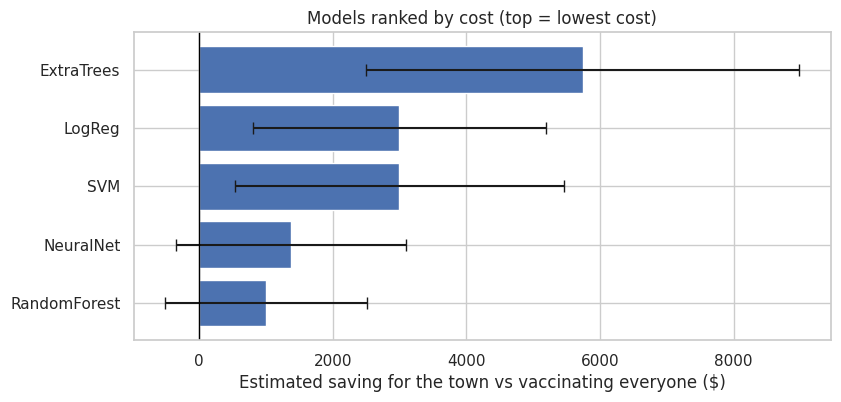

In [318]:
# Saving for the town vs vaccinating everyone (error bars = 1 std across the 15 CV folds)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cost_table.index[::-1], cost_table.saving_vs_vaccinate_all[::-1],
        xerr=(cost_table.cv_std * TOWN_POPULATION)[::-1], capsize=4,
        color=['#4c72b0' if v >= 0 else '#c44e52' for v in cost_table.saving_vs_vaccinate_all[::-1]])
ax.axvline(0, c='black', lw=1)
ax.set_xlabel('Estimated saving for the town vs vaccinating everyone ($)')
ax.set_title('Models ranked by cost (top = lowest cost)'); plt.show()

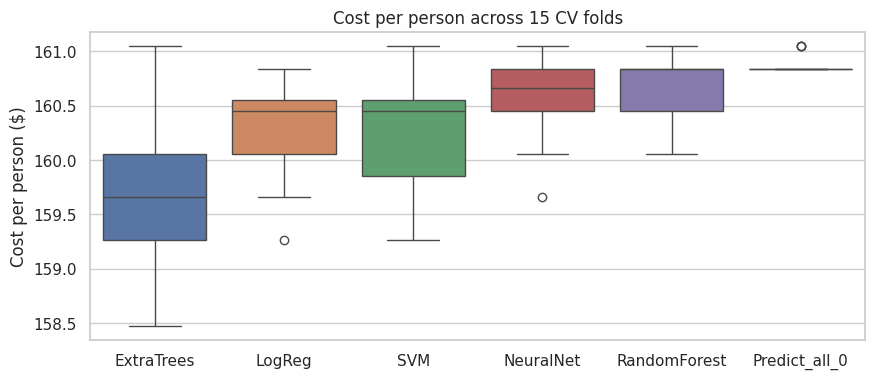

In [319]:
# Fold-by-fold cost for every model
folds = pd.DataFrame({name: r['rcv_cost_pp_folds'] for name, r in results.items()})
folds['Predict_all_0'] = baseline_folds
plt.figure(figsize=(10, 4))
sns.boxplot(data=folds[list(cost_table.index) + ['Predict_all_0']])
plt.ylabel('Cost per person ($)'); plt.title('Cost per person across 15 CV folds'); plt.show()

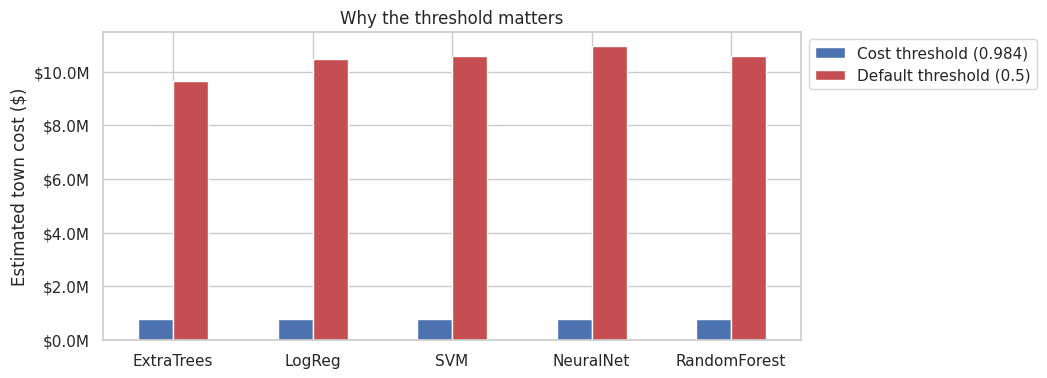

In [320]:
# Cost-optimal threshold vs default 0.5 threshold
comp = cost_table[['est_town_cost', 'town_cost_at_t0.5']].rename(
    columns={'est_town_cost': f'Cost threshold ({THRESHOLD:.3f})', 'town_cost_at_t0.5': 'Default threshold (0.5)'})
ax = comp.plot.bar(figsize=(9, 4), color=['#4c72b0', '#c44e52'])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v / 1e6:.1f}M'))
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); ax.set_xlabel('')
ax.set_ylabel('Estimated town cost ($)'); ax.set_title('Why the threshold matters')
plt.xticks(rotation=0); plt.show()

In [321]:
best = cost_table.index[0]
print(f'Lowest-cost model for the town: {best}')
print(f'Estimated town cost: ${cost_table.loc[best, "est_town_cost"]:,.0f}')
print(f'Saving vs vaccinating everyone: ${cost_table.loc[best, "saving_vs_vaccinate_all"]:,.0f}')

Lowest-cost model for the town: ExtraTrees
Estimated town cost: $758,293
Saving vs vaccinating everyone: $5,742


**Final ranking (lowest cost for the town first)**

| Rank | Model | Est. town cost | Saving vs vaccinating everyone |
|---|---|---|---|
| 1 | Extra Trees | ≈ \$758,300 | ≈ \$5,700 |
| 2 | Logistic regression | ≈ \$761,000 | ≈ \$3,000 |
| 3 | SVM | ≈ \$761,000 | ≈ \$3,000 |
| 4 | Neural network | ≈ \$762,700 | ≈ \$1,400 |
| 5 | Random forest | ≈ \$763,000 | ≈ \$1,000 |

- **Extra Trees gives the lowest cost for the town**, saving almost twice as much as the next model.
- **All five models save money** against vaccinating everyone, and each one beats or matches that baseline on every one of the 15 CV folds.
- Logistic regression and SVM are essentially tied. SVM was slightly better on the hold-out set, but we rank by the 15-fold CV estimate, which is more reliable.
- With the default 0.5 threshold, every model would cost the town about **\$10 million**, roughly 13–14× more. The cost-based threshold matters far more than the choice of model.

### Cost sensitivity analysis
The brief does not give the cost formula, so we check whether the ranking holds under other reasonable interpretations, using each model's hold-out probabilities.
If hospitalisation is not certain (probability $h$), the cost of a false positive becomes $h \times$ \$18,500.

In [322]:
SCENARIOS = {
    'Main: FP=18500, FN=300': {'TP': 0, 'TN': 0, 'FP': 18_500, 'FN': 300},
    'h=10%: FP=1850': {'TP': 0, 'TN': 0, 'FP': 1_850, 'FN': 300},
    'h=5%: FP=925': {'TP': 0, 'TN': 0, 'FP': 925, 'FN': 300},
}
hold_proba = {name: pd.read_csv(f'{RESULTS_DIR}/{name}_holdout_proba.csv', index_col=0)['p']
              .reindex(X_hold.index).values for name in MODEL_NAMES}

In [323]:
sens = {}
for scen, c in SCENARIOS.items():
    t = bayes_threshold(c)
    sens[f'{scen} (t={t:.3f})'] = {name: cost_per_person(y_hold, (p >= t).astype(int), c)
                                    for name, p in hold_proba.items()}
    sens[f'{scen} (t={t:.3f})']['Predict_all_0'] = cost_per_person(y_hold, np.zeros(len(y_hold)), c)
pd.DataFrame(sens).round(2)

,"Main: FP=18500, FN=300 (t=0.984)",h=10%: FP=1850 (t=0.860),h=5%: FP=925 (t=0.755)
LogReg,160.71,130.41,102.49
RandomForest,161.03,135.40,115.34
NeuralNet,160.71,125.37,108.93
ExtraTrees,160.71,137.66,121.98
SVM,160.40,127.99,109.30
Predict_all_0,161.03,161.03,161.03


### Submission – five models ranked by cost
Each model's test predictions are copied into `submissions/`, numbered by the cost ranking (rank 1 = lowest expected cost for the town).

> ⚠️ Check the column names and format against the official submission instructions.

In [324]:
TEAM_NAME = 'TeamC'
os.makedirs('submissions', exist_ok=True)
for rank, name in enumerate(cost_table.index, start=1):
    sub = pd.read_csv(f'{RESULTS_DIR}/{name}_test_predictions.csv')
    assert len(sub) == len(test) and set(sub.columns) == {'respondent_id', TARGET}
    path = f'submissions/{TEAM_NAME}_rank{rank}_{name}.csv'
    sub.to_csv(path, index=False)
    print(f'{path}: {sub[TARGET].sum()} respondents predicted as vaccinated')

submissions/TeamC_rank1_ExtraTrees.csv: 10 respondents predicted as vaccinated
submissions/TeamC_rank2_LogReg.csv: 12 respondents predicted as vaccinated
submissions/TeamC_rank3_SVM.csv: 14 respondents predicted as vaccinated
submissions/TeamC_rank4_NeuralNet.csv: 5 respondents predicted as vaccinated
submissions/TeamC_rank5_RandomForest.csv: 0 respondents predicted as vaccinated


In [325]:
try:
    from google.colab import files
    import shutil
    shutil.make_archive('submissions', 'zip', 'submissions')
    files.download('submissions.zip')
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusions
- **Metric:** total misclassification cost. Wrongly assuming someone is vaccinated costs \$18,500, and an unnecessary vaccine costs \$300. This gives a decision threshold of **0.984**.
- **Ranking by cost for the town:** 1 Extra Trees, 2 Logistic regression, 3 SVM, 4 Neural network, 5 Random forest. All five beat the "vaccinate everyone" baseline.
- **Why savings are small:** one wrong "vaccinated" call costs as much as about 60 unnecessary vaccines, so a model can only act on the few people it is almost certain about.
  Well-regularised models that average many opinions (Extra Trees) or shrink coefficients (logistic regression) do this best.
- **Sensitivity:** if hospitalisation is less certain, every model saves far more (e.g. about \$40–60 per person at $h$ = 5%). The neural network (at $h$ = 10%) and logistic regression (at $h$ = 5%) then come out best, and Extra Trees comes last, so the ranking depends on the cost interpretation.
- **Drivers of vaccination**, consistent across all five models: perceived risk of flu, doctor recommendation, age and belief in vaccine effectiveness.